# Main Paper Figures

## Figure 1: NSIDC SIC co-located with the Four Regional Arctic Locations Selected with this Study

The spin-up information was added in Microsoft Powerpoint, and can be easily replicated if desired.

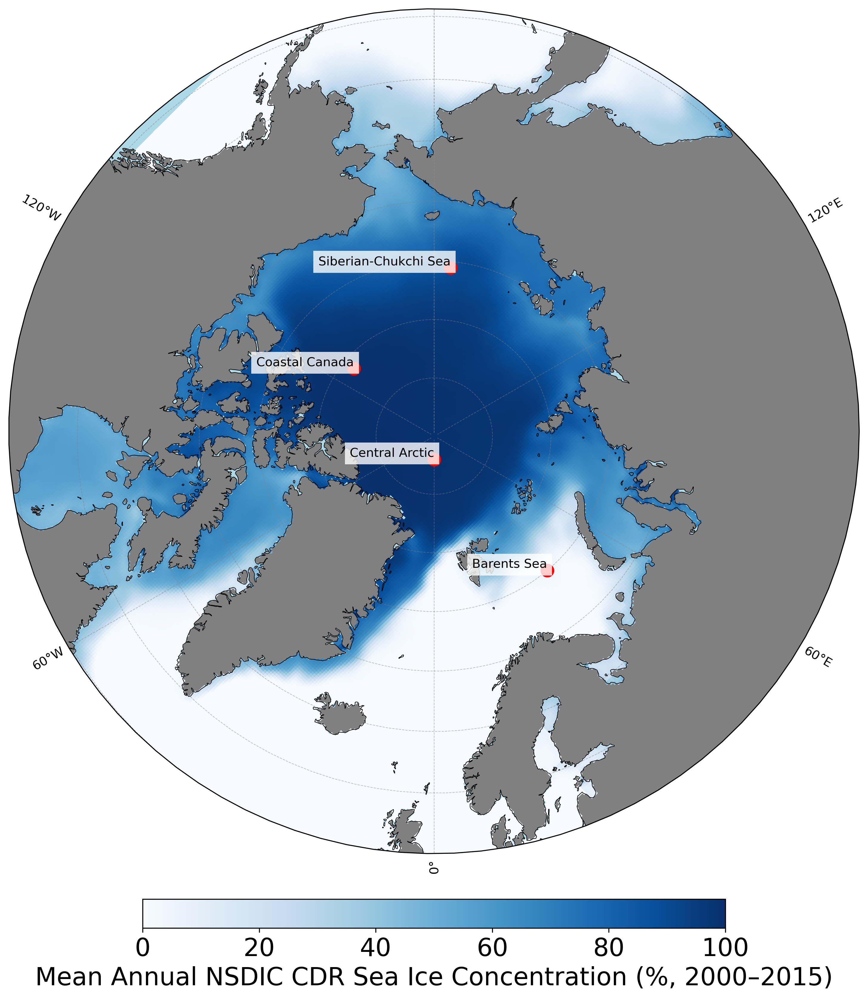

In [8]:
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.path as mpath
from pyproj import Transformer

# File paths and settings
data_dir = '/glade/u/home/jrotondo/work/Projects/cice-scm-da/data/NSIDC'
years = range(2000, 2016)
annual_means = []

# Load lat/lon from first available file
for y in years:
    for m in range(1, 13):
        for sensor in ['F17', 'F13']:
            fname = f'sic_psn25_{y}{m:02d}_{sensor}_v05r00.nc'
            fpath = os.path.join(data_dir, fname)
            if os.path.exists(fpath):
                ds = xr.open_dataset(fpath)
                x = ds['x'].values
                y = ds['y'].values
                xx, yy = np.meshgrid(x, y)

                # Projection: EPSG:3411 (NSIDC North Polar Stereographic)
                transformer = Transformer.from_crs("EPSG:3411", "EPSG:4326", always_xy=True)
                lon, lat = transformer.transform(xx, yy)
                break
        else:
            continue
        break
    else:
        continue
    break

# Loop through files and build annual stacks
for year in years:
    monthly_sic = []
    for month in range(1, 13):
        file_f17 = f'sic_psn25_{year}{month:02d}_F17_v05r00.nc'
        file_f13 = f'sic_psn25_{year}{month:02d}_F13_v05r00.nc'

        if os.path.exists(os.path.join(data_dir, file_f17)):
            file_path = os.path.join(data_dir, file_f17)
        elif os.path.exists(os.path.join(data_dir, file_f13)):
            file_path = os.path.join(data_dir, file_f13)
        else:
            print(f"Missing: {file_f17} and {file_f13}")
            continue

        ds = xr.open_dataset(file_path)
        sic = ds['cdr_seaice_conc_monthly'].squeeze()
        monthly_sic.append(sic)

    if monthly_sic:
        annual_mean = xr.concat(monthly_sic, dim='time').mean(dim='time')
        annual_means.append(annual_mean)

# Mean across years
mean_sic = xr.concat(annual_means, dim='year').mean(dim='year').values * 100

# --- Plotting ---
fig, ax = plt.subplots(
    figsize=(12, 14), dpi=300,
    subplot_kw={'projection': ccrs.NorthPolarStereo()}
)

# Mask circle for pole
theta = np.linspace(0, 2 * np.pi, 100)
r = 1.2
circle = mpath.Path(np.column_stack([
    0.5 + 0.5 * r * np.cos(theta),
    0.5 + 0.5 * r * np.sin(theta)
]))
ax.set_boundary(circle, transform=ax.transAxes)

# Map setup
ax.set_extent([-180, 180, 60, 90], crs=ccrs.PlateCarree())
ax.set_facecolor('lightblue')
ax.add_feature(cfeature.LAND, facecolor='gray')
ax.add_feature(cfeature.COASTLINE, edgecolor='black', linewidth=0.5)

# Plot SIC
sic_plot = ax.pcolormesh(
    lon, lat, mean_sic,
    transform=ccrs.PlateCarree(),
    cmap='Blues', vmin=0, vmax=100
)

cb = fig.colorbar(sic_plot, orientation='horizontal', pad=0.12, shrink=0.7, ax=ax)
cb.set_label('Mean Annual NSDIC CDR Sea Ice Concentration (%, 2000–2015)')

# Add latitude/longitude gridlines
gl = ax.gridlines(
    draw_labels=True,
    dms=True,
    x_inline=False,
    y_inline=False,
    linewidth=0.5,
    color='gray',
    alpha=0.5,
    linestyle='--'
)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {'size': 10, 'color': 'black'}
gl.ylabel_style = {'size': 10, 'color': 'black'}

# Arctic locations
locs = {
    'Barents Sea': [1.309, 0.698132],
    'Coastal Canada': [1.41372, -2.26893],
    'Siberian-Chukchi Sea': [1.3183906501, 3.0446500856],
    'Central Arctic': [1.53589, 0]
}
for loc, (lat_rad, lon_rad) in locs.items():
    lat_deg = np.degrees(lat_rad)
    lon_deg = (np.degrees(lon_rad) + 180) % 360 - 180
    ax.plot(lon_deg, lat_deg, 'ro', markersize=10, transform=ccrs.PlateCarree())
    ax.text(
        lon_deg, lat_deg, loc, transform=ccrs.PlateCarree(),
        fontsize=10, ha='right', va='bottom',
        bbox=dict(facecolor='white', alpha=0.8, edgecolor='none')
    )

plt.rcParams.update({'font.size': 18})
plt.rcParams['axes.titlesize'] = 18
plt.show()

## Figure 2: SIC Spin-up of the Free Ensemble

Note how different the ice states are for each region. This was desired to test to impacts of assimilation on different ice regimes.

<>:37: SyntaxWarning: invalid escape sequence '\m'
<>:37: SyntaxWarning: invalid escape sequence '\m'
/glade/derecho/scratch/jrotondo/tmp/ipykernel_123932/643107164.py:37: SyntaxWarning: invalid escape sequence '\m'
  plt.plot(time, preassim_var, label=f'{region}' + ' $\mu$', color=color)
/glade/derecho/scratch/jrotondo/tmp/ipykernel_123932/643107164.py:34: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  time = preassim_var['time'].to_index().to_datetimeindex()
/glade/derecho/scratch/jrotondo/tmp/ipykernel_123932/643107164.py:34: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'noleap', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between

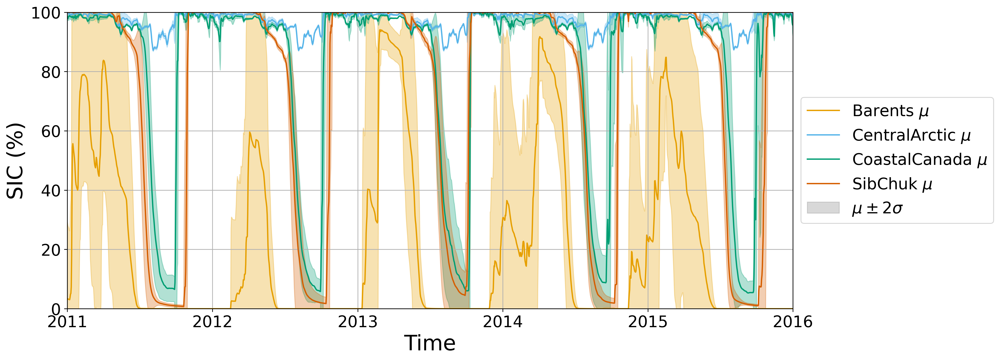

In [7]:
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Define the file paths and variable name
#regions = ["Barents", "CentralArctic", "CoastalCanada", "SibChuk"]
regions = ["Barents", "CentralArctic", "CoastalCanada", "SibChuk"]
#regions = ["SibChuk"]
directory_base = "/glade/work/jrotondo/Projects/cice-scm-da/data/processed/ensemble/free_"
var_name = "aicen"  # Sea Ice Concentration variable

# Define colors for each region
colors = ["#E69F00", "#56B4E9", "#009E73", "#D55E00"]   # orange, sky blue, bluish green, reddish orange
#colors = ["m"]

# Create the plot
plt.figure(figsize=(16, 6), dpi=300)
plt.rcParams.update({'font.size': 18})

for region, color in zip(regions, colors):
    #file_ensemble = f"{directory_base}{region}_final/postprocessed_ensemble.nc"
    file_ensemble = f"{directory_base}{region}_final_cat/postprocessed_ensemble.nc"
    
    # Open the dataset
    ds_ensemble = xr.open_dataset(file_ensemble)
    
    # Extract the desired data
    preassim_var = ds_ensemble[var_name].sum(dim='ncat').mean(dim='member') * 100
    preassim_sd = ds_ensemble[var_name].sum(dim='ncat').std(dim='member') * 100
    
    preassim_sd *= 2   # Convert to 2-sigma

    # Convert the time coordinate to datetime64 objects
    time = preassim_var['time'].to_index().to_datetimeindex()
    
    # Plot the data with time
    plt.plot(time, preassim_var, label=f'{region}' + ' $\mu$', color=color)
    plt.fill_between(
        time,
        preassim_var - preassim_sd,
        preassim_var + preassim_sd,
        color=color,
        alpha=0.3
    )

# Create a legend entry for the shading
shading_patch = mpatches.Patch(color="gray", alpha=0.3, label=r"$\mu \pm 2\sigma$")

#plt.title("Free-Run Mean SIC Distribution by Region")
plt.xlabel("Time")
plt.xlim([time[0], time[-1]])
plt.ylim(0, 100)
plt.ylabel("SIC (%)")
plt.legend(handles=[*plt.gca().get_legend_handles_labels()[0], shading_patch], loc='center left', bbox_to_anchor=(1, 0.5))  # Move legend outside the plot
plt.grid()
plt.tight_layout()
plt.show()

## Figure 3: Correlation Matrix of Icepack Variables

Included to show how certain Icepack variables interact with each other, and to justify combining narrow-band albedos into one broad-band SIAL for analysis.

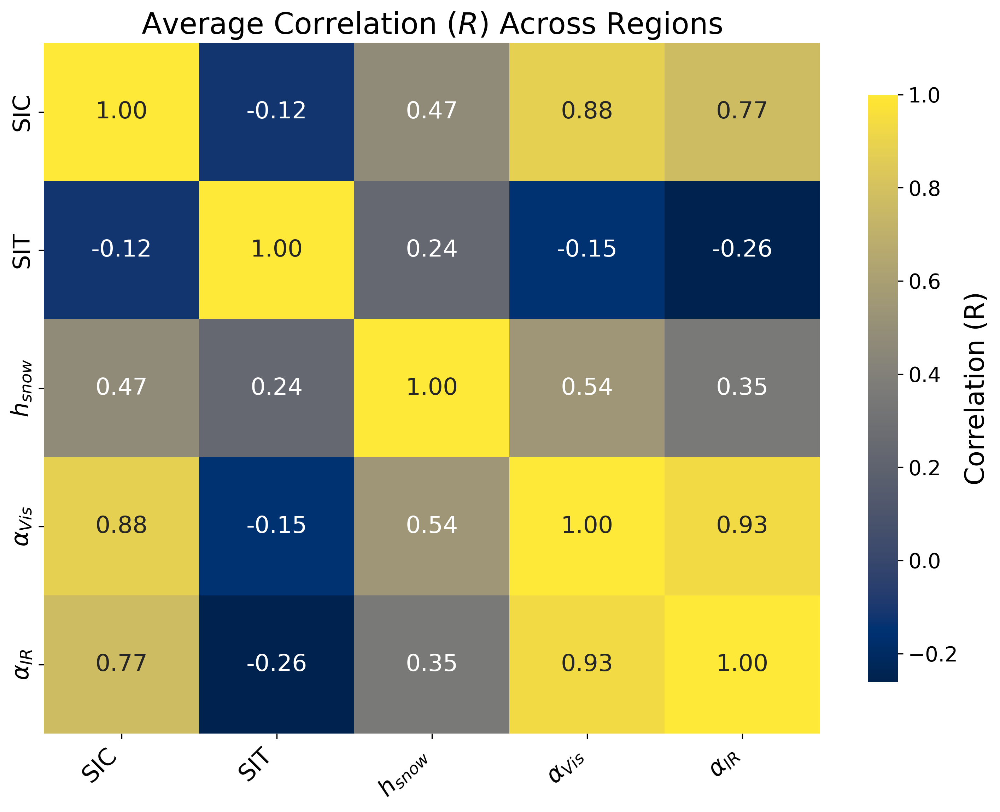

In [10]:
import numpy as np
import pandas as pd
import xarray as xr
import seaborn as sns
import matplotlib.pyplot as plt

# List of regions to analyze
regions = ['Barents', 'CentralArctic', 'CoastalCanada', 'SibChuk']

# Base directory
base_dir = '/glade/work/jrotondo/Projects/cice-scm-da/data/processed/ensemble/free_{}_final/'

# Initialize list for correlation matrices
corr_matrices = []

# Loop over regions
for region in regions:
    ds = xr.open_dataset(base_dir.format(region) + 'postprocessed_ensemble_res.nc')
    sic_cutoffs = {"Barents": 0.032, "CentralArctic": 0.000, "CoastalCanada": 0.018, "SibChuk": 0.173}
    sic = ds['aicen'].sum(dim='ncat')
    sic_mask = sic >= sic_cutoffs[region]

    # Base variables
    sic_vals = sic
    sit_vals = (ds['vicen'].sum(dim='ncat') / sic).where(sic_mask)
    hsnow_vals = (ds['vsnon'].sum(dim='ncat') / sic).where(sic_mask)

    # Albedo: average Dir and Ind for each wavelength
    albedo_vis = 0.5 * (ds['alvdr'] + ds['alvdf']).where(sic_mask)
    albedo_ir = 0.5 * (ds['alidr'] + ds['alidf']).where(sic_mask)

    # Stack data
    data_list = [sic_vals, sit_vals, hsnow_vals, albedo_vis, albedo_ir]
    stacked = xr.concat(data_list, dim='variable')
    data = stacked.values.reshape(len(data_list), -1).T
    data_clean = data[~np.isnan(data).any(axis=1)]

    # Compute correlation matrix
    corr_matrix = np.corrcoef(data_clean, rowvar=False)
    corr_matrices.append(corr_matrix)

# Average correlation matrix across all regions
avg_corr_matrix = np.mean(np.array(corr_matrices), axis=0)

# Labels
variable_labels = ['SIC', 'SIT', '$h_{snow}$', r'$\alpha_{Vis}$', r'$\alpha_{IR}$']

# Plot correlation matrix
plt.figure(figsize=(10, 8), dpi=300)
cmap = plt.cm.cividis.copy()
cmap.set_bad(color='lightgray')

ax = sns.heatmap(
    avg_corr_matrix,
    annot=True,
    xticklabels=variable_labels,
    yticklabels=variable_labels,
    cmap=cmap,
    fmt='.2f',
    annot_kws={"size": 16},
    cbar_kws={"label": "Correlation (R)", "shrink": 0.85}
)

# Set title and font sizes
plt.title('Average Correlation (' + r'$R$' + ') Across Regions', fontsize=20)
plt.xticks(fontsize=16, rotation=45, ha='right')
plt.yticks(fontsize=16)

# Increase colorbar tick label size
ax.collections[0].colorbar.ax.tick_params(labelsize=14)

plt.tight_layout()
plt.show()

## Figure 4: SIC and SIT RMSE Comparisons across different Assimilation Experiments

First we must calculate the RMSEs at each location for each ensemble truth member run (10 total) and save those for further analysis to arrive upon our desired result.

These RMSEs are saved in a .csv file for further analysis (called rmse_results.csv).

In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
import numpy as np
import cftime

def compute_rmse(analysis, truth, dim=None):
    """Compute RMSE between analysis and truth, ignoring NaNs.
    
    If `dim` is provided (e.g., 'ensemble_member'), the RMSE is computed 
    for each member individually before averaging.
    """
    if dim:
        return np.sqrt(((analysis - truth) ** 2).where(~np.isnan(analysis - truth), drop=True).mean(dim='time')).mean(dim).item()
    else:
        return np.sqrt(((analysis - truth) ** 2).where(~np.isnan(analysis - truth), drop=True).mean())

def compute_rmse_per_member(analysis, truth, dim='ensemble_member'):
    """Compute RMSE for each ensemble member individually."""
    if dim in analysis.dims:
        rmse_per_member = []
        for member in analysis[dim]:
            rmse = compute_rmse(analysis.sel({dim: member}), truth)
            rmse_per_member.append(rmse)
        return np.array(rmse_per_member)
    else:
        raise ValueError(f"Dimension '{dim}' not found in analysis dataset.")

# Define directories and ensemble years
base_dir = "/glade/work/jrotondo/Projects/cice-scm-da/data/processed/"
years_em = [(2011, 3), (2012, 5), (2013, 10), (2013, 12), (2014, 14), (2015, 16), (2015, 19), (2016, 21), (2017, 25), (2018, 28)]

# Regions to process
regions = ["Barents", "CentralArctic", "CoastalCanada", "SibChuk"]
abbreviated_regions = ["Bar", "CArc", "CCan", "SChuk"]

# Metric-specific limits for y-axes
metric_limits = {
    "SIAL": (0, 0.15),
    "SIT": (0, 1),
    "SIC": (0, 20),
}

sic_cutoffs = {
    "Barents": 0.032,
    "CentralArctic": 0.000,
    "CoastalCanada": 0.018,
    "SibChuk": 0.173
}

# Create a list to collect all RMSE results
rmse_records = []

# Initialize figure
fig, axes = plt.subplots(3, 10, figsize=(100, 50), sharey=False, dpi=300)

# Font sizes
title_fontsize = 32
label_fontsize = 28
tick_fontsize = 24
legend_fontsize = 32
ytick_fontsize = 20

for col_idx, (year, em) in enumerate(years_em):
    year = 2011  # Override all years to 2011
    
    # Define directories
    albedo_low_error_dir = f"{base_dir}SIAL_{{Region}}_bounded_low_err_2011_em{em}"
    albedo_med_error_dir = f"{base_dir}SIAL_{{Region}}_bounded_med_err_2011_em{em}_s"
    albedo_high_error_dir = f"{base_dir}SIAL_{{Region}}_bounded_high_err_2011_em{em}_f"
    albedo_category_dir = f"{base_dir}SIAL_{{Region}}_bounded_2011_em{em}_cat"
    sic_dir = f"{base_dir}SIC_{{Region}}_bounded_2011_em{em}_f"
    sit_dir = f"{base_dir}SIT_{{Region}}_bounded_2011_em{em}"
    everything_dir = f"{base_dir}EVERYTHING_{{Region}}_bounded_med_err_2011_em{em}_f"
    free_run_dir = f"{base_dir}ensemble/free_{{Region}}_final"

    # RMSE placeholders
    sia_rmse = {'SIC': [], 'SIAL_low_err': [], 'SIAL_med_err': [], 'SIAL_high_err': [], 'SIAL_category': [], 'SIT': [], 'All vars': [], 'Free run': []}
    sit_rmse = {'SIC': [], 'SIAL_low_err': [], 'SIAL_med_err': [], 'SIAL_high_err': [], 'SIAL_category': [], 'SIT': [], 'All vars': [], 'Free run': []}
    sic_rmse = {'SIC': [], 'SIAL_low_err': [], 'SIAL_med_err': [], 'SIAL_high_err': [], 'SIAL_category': [], 'SIT': [], 'All vars': [], 'Free run': []}
    
    for region in regions:
        print(f"\nProcessing Region: {region}, Ensemble: {em}")

        # File paths
        sic_path = sic_dir.format(Region=region)
        albedo_low_error_path = albedo_low_error_dir.format(Region=region)
        albedo_med_error_path = albedo_med_error_dir.format(Region=region)
        albedo_high_error_path = albedo_high_error_dir.format(Region=region)
        albedo_category_path = albedo_category_dir.format(Region=region)
        sit_path = sit_dir.format(Region=region)
        everything_path = everything_dir.format(Region=region)
        free_run_path = free_run_dir.format(Region=region)
        
        truth_file = f"{sic_path}/truth_data_{em:04d}.nc"
        analysis_sic_file = f"{sic_path}/analysis_ens.nc"
        analysis_albedo_low_error_file = f"{albedo_low_error_path}/analysis_ens.nc"
        analysis_albedo_med_error_file = f"{albedo_med_error_path}/analysis_ens.nc"
        analysis_albedo_high_error_file = f"{albedo_high_error_path}/analysis_ens.nc"
        analysis_albedo_category_file = f"{albedo_category_path}/analysis_ens.nc"
        analysis_sit_file = f"{sit_path}/analysis_ens.nc"
        analysis_everything_file = f"{everything_path}/analysis_ens.nc"
        free_run_file = f"{free_run_path}/postprocessed_ensemble.nc"
        
    
        # Check if files exist
        if not all(os.path.exists(f) for f in [truth_file, analysis_sic_file, analysis_albedo_low_error_file, analysis_albedo_med_error_file, analysis_albedo_high_error_file, analysis_albedo_category_file, analysis_sit_file, free_run_file]):
            print(f"Skipping {region}, Em {em} due to missing files.")
            continue
        
        # Load datasets
        truth_ds = xr.open_dataset(truth_file)
        analysis_sic_ds = xr.open_dataset(analysis_sic_file)
        analysis_albedo_ds_low_error = xr.open_dataset(analysis_albedo_low_error_file)
        analysis_albedo_ds_med_error = xr.open_dataset(analysis_albedo_med_error_file)
        analysis_albedo_ds_high_error = xr.open_dataset(analysis_albedo_high_error_file)
        analysis_albedo_ds_category = xr.open_dataset(analysis_albedo_category_file)
        analysis_sit_ds = xr.open_dataset(analysis_sit_file)
        analysis_everything_ds = xr.open_dataset(analysis_everything_file)
        free_run_ds = xr.open_dataset(free_run_file)
       
        # Reference date matching your truth_ds
        reference_date = cftime.DatetimeNoLeap(year, 4, 1)

        # Convert free_run_ds time values to days since the reference date
        free_run_time = np.array([(t - reference_date).days for t in free_run_ds['time'].values], dtype=np.int64)

        # Replace the 'time' coordinate in free_run_ds with the converted values
        free_run_ds = free_run_ds.assign_coords(time=free_run_time)

        # Compute common time
        common_time = np.intersect1d(truth_ds['time'], analysis_sic_ds['time'])
        common_time = np.intersect1d(common_time, analysis_albedo_ds_low_error['time'])
        common_time = np.intersect1d(common_time, analysis_albedo_ds_med_error['time'])
        common_time = np.intersect1d(common_time, analysis_albedo_ds_high_error['time'])
        common_time = np.intersect1d(common_time, analysis_albedo_ds_category['time'])
        common_time = np.intersect1d(common_time, analysis_sit_ds['time'])
        common_time = np.intersect1d(common_time, analysis_everything_ds['time'])
        common_time = np.intersect1d(common_time, free_run_ds['time'])

        # Check common time length before selection
        if len(common_time) == 0:
            print(f"Skipping {region}, Em {em}: No common time values found!")
            continue

        # Apply selection
        truth_ds = truth_ds.sel(time=common_time)
        analysis_sic_ds = analysis_sic_ds.sel(time=common_time)
        analysis_albedo_ds_low_error = analysis_albedo_ds_low_error.sel(time=common_time)
        analysis_albedo_ds_med_error = analysis_albedo_ds_med_error.sel(time=common_time)
        analysis_albedo_ds_high_error = analysis_albedo_ds_high_error.sel(time=common_time)
        analysis_albedo_ds_category = analysis_albedo_ds_category.sel(time=common_time)
        analysis_sit_ds = analysis_sit_ds.sel(time=common_time)
        analysis_everything_ds = analysis_everything_ds.sel(time=common_time)
        free_run_ds = free_run_ds.sel(time=common_time)

        # Weights for visible and near-infrared bands
        awtvdf, awtvdr = 0.63282, 0.00318  # Visible: diffuse and direct
        awtidf, awtidr = 0.36218, 0.00182  # Near-infrared: diffuse and direct

        # Compute Broadband Albedo (SIA)
        sia_truth = (
            (awtvdr * truth_ds['alvdr'] + awtvdf * truth_ds['alvdf']) +
            (awtidr * truth_ds['alidr'] + awtidf * truth_ds['alidf'])
        ).sel(ni=2)

        sia_sic = (
            (awtvdr * analysis_sic_ds['alvdr'] + awtvdf * analysis_sic_ds['alvdf']) +
            (awtidr * analysis_sic_ds['alidr'] + awtidf * analysis_sic_ds['alidf'])
        ).sel(ni=2)

        sia_albedo_only_high_error = (
            (awtvdr * analysis_albedo_ds_high_error['alvdr'] + awtvdf * analysis_albedo_ds_high_error['alvdf']) +
            (awtidr * analysis_albedo_ds_high_error['alidr'] + awtidf * analysis_albedo_ds_high_error['alidf'])
        ).sel(ni=2)

        sia_albedo_only_low_error = (
            (awtvdr * analysis_albedo_ds_low_error['alvdr'] + awtvdf * analysis_albedo_ds_low_error['alvdf']) +
            (awtidr * analysis_albedo_ds_low_error['alidr'] + awtidf * analysis_albedo_ds_low_error['alidf'])
        ).sel(ni=2)

        sia_albedo_only_med_error = (
            (awtvdr * analysis_albedo_ds_med_error['alvdr'] + awtvdf * analysis_albedo_ds_med_error['alvdf']) +
            (awtidr * analysis_albedo_ds_med_error['alidr'] + awtidf * analysis_albedo_ds_med_error['alidf'])
        ).sel(ni=2)

        ''' sia_albedo_category = (
            (awtvdr * analysis_albedo_ds_category['alvdr'] + awtvdf * analysis_albedo_ds_category['alvdf']) +
            (awtidr * analysis_albedo_ds_category['alidr'] + awtidf * analysis_albedo_ds_category['alidf'])
        ).sel(ni=2)'''

        sia_sit = (
            (awtvdr * analysis_sit_ds['alvdr'] + awtvdf * analysis_sit_ds['alvdf']) +
            (awtidr * analysis_sit_ds['alidr'] + awtidf * analysis_sit_ds['alidf'])
        ).sel(ni=2)

        sia_everything = (
            (awtvdr * analysis_everything_ds['alvdr'] + awtvdf * analysis_everything_ds['alvdf']) +
            (awtidr * analysis_everything_ds['alidr'] + awtidf * analysis_everything_ds['alidf'])
        ).sel(ni=2)
        
        # Compute SIT
        sit_truth = truth_ds['vicen'].sum(dim='ncat').sel(ni=2) / truth_ds['aicen'].sum(dim='ncat').sel(ni=2)
        sit_sic = analysis_sic_ds['vicen'].sum(dim='ncat').sel(ni=2) / analysis_sic_ds['aicen'].sum(dim='ncat').sel(ni=2)
        sit_albedo_only_low_error = analysis_albedo_ds_low_error['vicen'].sum(dim='ncat').sel(ni=2) / analysis_albedo_ds_low_error['aicen'].sum(dim='ncat').sel(ni=2)
        sit_albedo_only_med_error = analysis_albedo_ds_med_error['vicen'].sum(dim='ncat').sel(ni=2) / analysis_albedo_ds_med_error['aicen'].sum(dim='ncat').sel(ni=2)
        sit_albedo_only_high_error = analysis_albedo_ds_high_error['vicen'].sum(dim='ncat').sel(ni=2) / analysis_albedo_ds_high_error['aicen'].sum(dim='ncat').sel(ni=2)
        sit_albedo_category = analysis_albedo_ds_category['vicen'].sum(dim='ncat').sel(ni=2) / analysis_albedo_ds_category['aicen'].sum(dim='ncat').sel(ni=2)
        sit_sit = analysis_sit_ds['vicen'].sum(dim='ncat').sel(ni=2) / analysis_sit_ds['aicen'].sum(dim='ncat').sel(ni=2)
        sit_everything = analysis_everything_ds['vicen'].sum(dim='ncat').sel(ni=2) / analysis_everything_ds['aicen'].sum(dim='ncat').sel(ni=2)
        sit_free_run = free_run_ds['vicen'].sum(dim='ncat') / free_run_ds['aicen'].sum(dim='ncat')

        # Get the SIC cutoff for the current region
        sic_cutoff = sic_cutoffs.get(region, 0)

        # Apply SIC cutoff to SIT values
        sit_truth = xr.where(truth_ds['aicen'].sum(dim='ncat').sel(ni=2) < sic_cutoff, np.nan, sit_truth)
        sit_sic = xr.where(analysis_sic_ds['aicen'].sum(dim='ncat').sel(ni=2) < sic_cutoff, np.nan, sit_sic)
        sit_albedo_only_low_error = xr.where(analysis_albedo_ds_low_error['aicen'].sum(dim='ncat').sel(ni=2) < sic_cutoff, np.nan, sit_albedo_only_low_error)
        sit_albedo_only_med_error = xr.where(analysis_albedo_ds_med_error['aicen'].sum(dim='ncat').sel(ni=2) < sic_cutoff, np.nan, sit_albedo_only_med_error)
        sit_albedo_only_high_error = xr.where(analysis_albedo_ds_high_error['aicen'].sum(dim='ncat').sel(ni=2) < sic_cutoff, np.nan, sit_albedo_only_high_error)
        sit_albedo_category = xr.where(analysis_albedo_ds_category['aicen'].sum(dim='ncat').sel(ni=2) < sic_cutoff, np.nan, sit_albedo_category)
        sit_sit = xr.where(analysis_sit_ds['aicen'].sum(dim='ncat').sel(ni=2) < sic_cutoff, np.nan, sit_sit)
        sit_everything = xr.where(analysis_everything_ds['aicen'].sum(dim='ncat').sel(ni=2) < sic_cutoff, np.nan, sit_everything)
        sit_free_run = xr.where(free_run_ds['aicen'].sum(dim='ncat') < sic_cutoff, np.nan, sit_free_run)
        
        # Compute SIC
        sic_truth = truth_ds['aicen'].sum(dim='ncat').sel(ni=2) * 100
        sic_sic = analysis_sic_ds['aicen'].sum(dim='ncat').sel(ni=2) * 100
        sic_albedo_only_low_error = analysis_albedo_ds_low_error['aicen'].sum(dim='ncat').sel(ni=2) * 100
        sic_albedo_only_med_error = analysis_albedo_ds_med_error['aicen'].sum(dim='ncat').sel(ni=2) * 100
        sic_albedo_only_high_error = analysis_albedo_ds_high_error['aicen'].sum(dim='ncat').sel(ni=2) * 100
        sic_albedo_category = analysis_albedo_ds_category['aicen'].sum(dim='ncat').sel(ni=2) * 100
        sic_sit = analysis_sit_ds['aicen'].sum(dim='ncat').sel(ni=2) * 100
        sic_everything = analysis_everything_ds['aicen'].sum(dim='ncat').sel(ni=2) * 100
        sic_free_run = free_run_ds['aicen'].sum(dim='ncat') * 100

        # Compute RMSE and store results
        sia_rmse['SIC'].append(compute_rmse(sia_sic, sia_truth, dim='ensemble_member'))
        sia_rmse['SIAL_low_err'].append(compute_rmse(sia_albedo_only_low_error, sia_truth, dim='ensemble_member'))
        sia_rmse['SIAL_med_err'].append(compute_rmse(sia_albedo_only_med_error, sia_truth, dim='ensemble_member'))
        sia_rmse['SIAL_high_err'].append(compute_rmse(sia_albedo_only_high_error, sia_truth))
        #sia_rmse['SIAL_category'].append(compute_rmse(sia_albedo_category, sia_truth, dim='ensemble_member'))
        sia_rmse['SIT'].append(compute_rmse(sia_sit, sia_truth, dim='ensemble_member'))
        sia_rmse['All vars'].append(compute_rmse(sia_everything, sia_truth, dim='ensemble_member'))
        
        sit_rmse['SIC'].append(compute_rmse(sit_sic, sit_truth, dim='ensemble_member'))
        sit_rmse['SIAL_low_err'].append(compute_rmse(sit_albedo_only_low_error, sit_truth, dim='ensemble_member'))
        sit_rmse['SIAL_med_err'].append(compute_rmse(sit_albedo_only_med_error, sit_truth, dim='ensemble_member'))
        sit_rmse['SIAL_high_err'].append(compute_rmse(sit_albedo_only_high_error, sit_truth, dim='ensemble_member'))
        sit_rmse['SIAL_category'].append(compute_rmse(sit_albedo_category, sit_truth, dim='ensemble_member'))
        sit_rmse['SIT'].append(compute_rmse(sit_sit, sit_truth, dim='ensemble_member'))
        sit_rmse['All vars'].append(compute_rmse(sit_everything, sit_truth, dim='ensemble_member'))
        sit_rmse['Free run'].append(compute_rmse(sit_free_run, sit_truth, dim='member'))
        
        sic_rmse['SIC'].append(compute_rmse(sic_sic, sic_truth, dim='ensemble_member'))
        sic_rmse['SIAL_low_err'].append(compute_rmse(sic_albedo_only_low_error, sic_truth, dim='ensemble_member'))
        sic_rmse['SIAL_med_err'].append(compute_rmse(sic_albedo_only_med_error, sic_truth, dim='ensemble_member'))
        sic_rmse['SIAL_high_err'].append(compute_rmse(sic_albedo_only_high_error, sic_truth, dim='ensemble_member'))
        sic_rmse['SIAL_category'].append(compute_rmse(sic_albedo_category, sic_truth, dim='ensemble_member'))
        sic_rmse['SIT'].append(compute_rmse(sic_sit, sic_truth, dim='ensemble_member'))
        sic_rmse['All vars'].append(compute_rmse(sic_everything, sic_truth, dim='ensemble_member'))
        sic_rmse['Free run'].append(compute_rmse(sic_free_run, sic_truth, dim='member'))

        # Store the RMSE results for each ensemble member
        sia_rmse_values = {
            "region": region,
            "ensemble_number": em,
            "metric": "SIA",
            "SIC": compute_rmse_per_member(sia_sic, sia_truth).tolist(),
            "SIAL_low_err": compute_rmse_per_member(sia_albedo_only_low_error, sia_truth).tolist(),
            "SIAL_med_err": compute_rmse_per_member(sia_albedo_only_med_error, sia_truth).tolist(),
            "SIAL_high_err": compute_rmse_per_member(sia_albedo_only_high_error, sia_truth).tolist(),
            #"SIAL_category": compute_rmse_per_member(sia_albedo_category, sia_truth).tolist(),
            "SIT": compute_rmse_per_member(sia_sit, sia_truth).tolist(),
            "All_vars": compute_rmse_per_member(sia_everything, sia_truth).tolist(),
            "mean_SIC": compute_rmse(sia_sic, sia_truth, dim='ensemble_member'),
            "mean_SIAL_low_err": compute_rmse(sia_albedo_only_low_error, sia_truth, dim='ensemble_member'),
            "mean_SIAL_med_err": compute_rmse(sia_albedo_only_med_error, sia_truth, dim='ensemble_member'),
            "mean_SIAL_high_err": compute_rmse(sia_albedo_only_high_error, sia_truth, dim='ensemble_member'),
            "mean_SIT": compute_rmse(sia_sit, sia_truth, dim='ensemble_member'),
            "mean_All_vars": compute_rmse(sia_everything, sia_truth, dim='ensemble_member'),
            "std_SIC": np.nanstd(compute_rmse_per_member(sia_sic, sia_truth)),
            "std_SIAL_low_err": np.nanstd(compute_rmse_per_member(sia_albedo_only_low_error, sia_truth)),
            "std_SIAL_med_err": np.nanstd(compute_rmse_per_member(sia_albedo_only_med_error, sia_truth)),
            "std_SIAL_high_err": np.nanstd(compute_rmse_per_member(sia_albedo_only_high_error, sia_truth)),
            "std_SIT": np.nanstd(compute_rmse_per_member(sia_sit, sia_truth)),
            "std_All_vars": np.nanstd(compute_rmse_per_member(sia_everything, sia_truth)),
        }
        rmse_records.append(sia_rmse_values)

        sit_rmse_values = {
            "region": region,
            "ensemble_number": em,
            "metric": "SIT",
            "SIC": compute_rmse_per_member(sit_sic, sit_truth).tolist(),
            "SIAL_low_err": compute_rmse_per_member(sit_albedo_only_low_error, sit_truth).tolist(),
            "SIAL_med_err": compute_rmse_per_member(sit_albedo_only_med_error, sit_truth).tolist(),
            "SIAL_high_err": compute_rmse_per_member(sit_albedo_only_high_error, sit_truth).tolist(),
            "SIAL_category": compute_rmse_per_member(sit_albedo_category, sit_truth).tolist(),
            "SIT": compute_rmse_per_member(sit_sit, sit_truth).tolist(),
            "All_vars": compute_rmse_per_member(sit_everything, sit_truth).tolist(),
            "Free_run": compute_rmse_per_member(sit_free_run, sit_truth, dim='member').tolist(),
            "mean_SIC": compute_rmse(sit_sic, sit_truth, dim='ensemble_member'),
            "mean_SIAL_low_err": compute_rmse(sit_albedo_only_low_error, sit_truth, dim='ensemble_member'),
            "mean_SIAL_med_err": compute_rmse(sit_albedo_only_med_error, sit_truth, dim='ensemble_member'),
            "mean_SIAL_high_err": compute_rmse(sit_albedo_only_high_error, sit_truth, dim='ensemble_member'),
            "mean_SIT": compute_rmse(sit_sit, sit_truth, dim='ensemble_member'),
            "mean_All_vars": compute_rmse(sit_everything, sit_truth, dim='ensemble_member'),
            "mean_Free_run": compute_rmse(sit_free_run, sit_truth, dim='member'),
            "mean_SIAL_category": compute_rmse(sit_albedo_category, sit_truth, dim='ensemble_member'),
            "std_SIC": np.nanstd(compute_rmse_per_member(sit_sic, sit_truth)),
            "std_SIAL_low_err": np.nanstd(compute_rmse_per_member(sit_albedo_only_low_error, sit_truth)),
            "std_SIAL_med_err": np.nanstd(compute_rmse_per_member(sit_albedo_only_med_error, sit_truth)),
            "std_SIAL_high_err": np.nanstd(compute_rmse_per_member(sit_albedo_only_high_error, sit_truth)),
            "std_SIT": np.nanstd(compute_rmse_per_member(sit_sit, sit_truth)),
            "std_All_vars": np.nanstd(compute_rmse_per_member(sit_everything, sit_truth)),
            "std_Free_run": np.nanstd(compute_rmse_per_member(sit_free_run, sit_truth, dim='member'))
        }
        rmse_records.append(sit_rmse_values)

        sic_rmse_values = {
            "region": region,
            "ensemble_number": em,
            "metric": "SIC",
            "SIC": compute_rmse_per_member(sic_sic, sic_truth).tolist(),
            "SIAL_low_err": compute_rmse_per_member(sic_albedo_only_low_error, sic_truth).tolist(),
            "SIAL_med_err": compute_rmse_per_member(sic_albedo_only_med_error, sic_truth).tolist(),
            "SIAL_high_err": compute_rmse_per_member(sic_albedo_only_high_error, sic_truth).tolist(),
            "SIAL_category": compute_rmse_per_member(sic_albedo_category, sic_truth).tolist(),
            "SIT": compute_rmse_per_member(sic_sit, sic_truth).tolist(),
            "All_vars": compute_rmse_per_member(sic_everything, sic_truth).tolist(),
            "Free_run": compute_rmse_per_member(sic_free_run, sic_truth, dim='member').tolist(),
            "mean_SIC": compute_rmse(sic_sic, sic_truth, dim='ensemble_member'),
            "mean_SIAL_low_err": compute_rmse(sic_albedo_only_low_error, sic_truth, dim='ensemble_member'),
            "mean_SIAL_med_err": compute_rmse(sic_albedo_only_med_error, sic_truth, dim='ensemble_member'),
            "mean_SIAL_high_err": compute_rmse(sic_albedo_only_high_error, sic_truth, dim='ensemble_member'),
            "mean_SIT": compute_rmse(sic_sit, sic_truth, dim='ensemble_member'),
            "mean_All_vars": compute_rmse(sic_everything, sic_truth, dim='ensemble_member'),
            "mean_Free_run": compute_rmse(sic_free_run, sic_truth, dim='member'),
            "mean_SIAL_category": compute_rmse(sic_albedo_category, sic_truth, dim='ensemble_member'),
            "std_SIC": np.nanstd(compute_rmse_per_member(sic_sic, sic_truth)),
            "std_SIAL_low_err": np.nanstd(compute_rmse_per_member(sic_albedo_only_low_error, sic_truth)),
            "std_SIAL_med_err": np.nanstd(compute_rmse_per_member(sic_albedo_only_med_error, sic_truth)),
            "std_SIAL_high_err": np.nanstd(compute_rmse_per_member(sic_albedo_only_high_error, sic_truth)),
            "std_SIT": np.nanstd(compute_rmse_per_member(sic_sit, sic_truth)),
            "std_All_vars": np.nanstd(compute_rmse_per_member(sic_everything, sic_truth)),
            "std_Free_run": np.nanstd(compute_rmse_per_member(sic_free_run, sic_truth, dim='member'))
        }
        rmse_records.append(sic_rmse_values)

    # Convert RMSE records to a DataFrame
    rmse_df = pd.DataFrame(rmse_records)

    # Save to CSV
    output_path = "/glade/work/jrotondo/Projects/cice-scm-da/data/rmse_results.csv"
    rmse_df.to_csv(output_path, index=False)

    print(f"RMSE results saved to {output_path}")

    metrics = ['SIAL', 'SIT', 'SIC']

    for row_idx, (metric, rmse_data) in enumerate(zip(metrics, [sia_rmse, sit_rmse, sic_rmse])):
        ax = axes[row_idx, col_idx]
        x = np.arange(len(sia_rmse['SIC']))
        width = 0.25

        group_spacing = 3  # Increase this for more space between groups

        x_grouped = x * group_spacing  # Apply spacing between groups

        ax.bar(x_grouped - 3.5 * width, rmse_data['SIC'], width, label='SIC')
        ax.bar(x_grouped - 2.5 * width, rmse_data['SIAL_low_err'], width, label='SIAL_low_err')
        ax.bar(x_grouped - 1.5 * width, rmse_data['SIAL_med_err'], width, label='SIAL_med_err')
        ax.bar(x_grouped - 0.5 * width, rmse_data['SIAL_high_err'], width, label='SIAL_high_err')
        if metric != 'SIAL':
            ax.bar(x_grouped + 0.5 * width, rmse_data['SIAL_category'], width, label='SIAL_category')
        ax.bar(x_grouped + 1.5 * width, rmse_data['SIT'], width, label='SIT')
        ax.bar(x_grouped + 2.5 * width, rmse_data['All vars'], width, label='All vars')
        if metric != 'SIAL':
            ax.bar(x_grouped + 3.5 * width, rmse_data['Free run'], width, label='Free run mean')
            
        if col_idx == 0:
            if metric == 'SIAL':
                ax.set_ylabel(f'{metric} RMSE (unitless)', fontsize=label_fontsize)
            elif metric == 'SIC':
                ax.set_ylabel(f'{metric} RMSE (%)', fontsize=label_fontsize)
            elif metric == 'SIT':
                ax.set_ylabel(f'{metric} RMSE (m)', fontsize=label_fontsize)
        if row_idx == 2:
            ax.set_xticks(x_grouped)
            ax.set_xticklabels(abbreviated_regions[:len(x_grouped)], fontsize=tick_fontsize)
        else:
            ax.set_xticks([])

        ax.set_ylim(metric_limits[metric])
        ax.set_title(f'Year 2011, Em {em}' if row_idx == 0 else "", fontsize=title_fontsize)
        ax.tick_params(axis='y', labelsize=ytick_fontsize)
                
        if row_idx == 2 and col_idx == 9:
            ax.legend(fontsize=legend_fontsize)

plt.tight_layout()
plt.show()



Processing Region: Barents, Ensemble: 3

Processing Region: CentralArctic, Ensemble: 3

Processing Region: CoastalCanada, Ensemble: 3

Processing Region: SibChuk, Ensemble: 3
RMSE results saved to /glade/work/jrotondo/Projects/cice-scm-da/data/rmse_results.csv

Processing Region: Barents, Ensemble: 5

Processing Region: CentralArctic, Ensemble: 5

Processing Region: CoastalCanada, Ensemble: 5

Processing Region: SibChuk, Ensemble: 5
RMSE results saved to /glade/work/jrotondo/Projects/cice-scm-da/data/rmse_results.csv

Processing Region: Barents, Ensemble: 10

Processing Region: CentralArctic, Ensemble: 10

Processing Region: CoastalCanada, Ensemble: 10

Processing Region: SibChuk, Ensemble: 10
RMSE results saved to /glade/work/jrotondo/Projects/cice-scm-da/data/rmse_results.csv

Processing Region: Barents, Ensemble: 12

Processing Region: CentralArctic, Ensemble: 12

Processing Region: CoastalCanada, Ensemble: 12

Processing Region: SibChuk, Ensemble: 12
RMSE results saved to /glade/w

Now, using the results from the csv file, we can take the average RMSE across the 10 different truth runs and use bootstrapping resample with replacement to calculate 95% C.I.s corresponding to the data. Note that bootstrapping was chosen to avoid the assumption that the RMSE values were normally distributed. This gives us the desired **Fig. 4**.

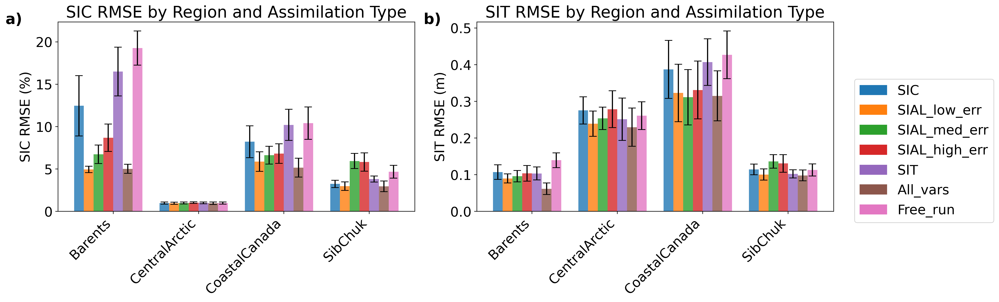

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load RMSE data
rmse_df = pd.read_csv("/glade/work/jrotondo/Projects/cice-scm-da/data/rmse_results.csv")

# Define full list of methods
full_methods = ["SIC", "SIAL_low_err", "SIAL_med_err", "SIAL_high_err", "SIT", "SIT_SIC", "All_vars", "Free_run"]

# Dynamically filter out missing methods
available_methods = [m for m in full_methods if f"mean_{m}" in rmse_df.columns and not rmse_df[f"mean_{m}"].isna().all()]

# Define metrics and unique regions
metrics = ["SIC", "SIT"]
regions = rmse_df["region"].unique()

# Create subplots for SIC and SIT
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=False, dpi=300)

# Use default Matplotlib color cycle
color_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]

# Subplot labels
subplot_labels = ["a)", "b)"]

for j, metric in enumerate(metrics):
    ax = axes[j]
    bar_width = 0.8 / len(available_methods)  # Adjust width dynamically
    x_positions = np.arange(len(regions))  # Base x positions for each region

    # Add subplot label
    ax.text(-0.1, 1.05, subplot_labels[j], transform=ax.transAxes, 
            fontsize=20, fontweight='bold', va='top', ha='right')

    for method_idx, method in enumerate(available_methods):
        means, ci95s = [], []
        for region in regions:
            region_df = rmse_df[(rmse_df["region"] == region) & (rmse_df["metric"] == metric)]
            col_name = f"mean_{method}"

            if col_name in region_df.columns and not region_df[col_name].isna().all():
                vals = region_df[col_name].dropna().values
                mean_val = np.mean(vals)

                # Bootstrap 95% CI
                boot_means = []
                n_boot = 1000
                rng = np.random.default_rng(seed=42)

                for _ in range(n_boot):
                    sample = rng.choice(vals, size=len(vals), replace=True)
                    boot_means.append(np.mean(sample))

                lower = np.percentile(boot_means, 2.5)
                upper = np.percentile(boot_means, 97.5)
                ci95 = upper - mean_val
            else:
                mean_val, ci95 = np.nan, np.nan

            means.append(mean_val)
            ci95s.append(ci95)

        color = color_cycle[method_idx % len(color_cycle)]

        ax.bar(x_positions + method_idx * bar_width, means, yerr=ci95s, capsize=5, width=bar_width,
               color=color, label=method if j == 0 else "", alpha=0.8)

    ax.set_xticks(x_positions + (len(available_methods) / 2) * bar_width)
    ax.set_xticklabels(regions, rotation=45, ha="right")
    ax.set_title(f"{metric} RMSE by Region and Assimilation Type")
    ax.set_ylabel(f"{metric} RMSE (%)" if metric == "SIC" else f"{metric} RMSE (m)")

# Add a single legend
handles = [plt.Rectangle((0,0),1,1, color=color_cycle[i % len(color_cycle)]) for i in range(len(available_methods))]
fig.legend(handles, available_methods, loc="center left", bbox_to_anchor=(1, 0.5))

plt.rcParams.update({'font.size': 18})
plt.rcParams.update({'axes.labelsize': 18})

plt.tight_layout()
plt.show()

## Figure 5: RMSE Comparison Metrics using Welsh T-Tests and Paired Wilcoxon Tests

The following code checks for whether two assimilation-type RMSE distributions for the 10 'truth' experiments are normally-distributed or not. If both are normally distributed, a standard Welsh paired T-Test is used to determine statistical significance. If at least one is not statistically significant, then the nonparametric paired Wilcoxon test is used.

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind, mannwhitneyu, shapiro, wilcoxon
import matplotlib.colors as mcolors
import pandas as pd
from matplotlib.patches import Patch

# Load RMSE data
rmse_df = pd.read_csv("/glade/work/jrotondo/Projects/cice-scm-da/data/rmse_results.csv")

# Define metrics and unique regions
metrics = ["SIC", "SIT"]
regions = rmse_df["region"].unique()

# Define full list of methods
full_methods = ["SIC", "SIAL_low_err", "SIAL_med_err", "SIAL_high_err", "SIT", "SIT_SIC", "All_vars", "Free_run"]

# Dynamically filter out missing methods
available_methods = [m for m in full_methods if f"mean_{m}" in rmse_df.columns and not rmse_df[f"mean_{m}"].isna().all()]

# Set plotting style
alpha = 0.05
n_metrics = 2
n_regions = len(regions)
n_rows = 2
n_cols_per_metric = n_regions
total_cols = n_cols_per_metric

fig, axes = plt.subplots(n_rows, total_cols, figsize=(40, 25), dpi=300)

plt.rcParams.update({'font.size': 20})
plt.rcParams.update({'axes.labelsize': 20})

subplot_labels = ['a)', 'b)', 'c)', 'd)', 'e)', 'f)', 'g)', 'h)']

for r_idx, region in enumerate(regions):
    for m_idx, metric in enumerate(metrics):
        row = m_idx
        col = r_idx
        ax = axes[row, col]
        label_idx = row * total_cols + col  # Compute flat index for label
        ax.text(-0.1, 1.05, subplot_labels[label_idx], transform=ax.transAxes,
        fontsize=24, fontweight='bold', va='top', ha='right')
        ax.set_title(f"{region} - {metric} RMSE", fontsize=22)

        region_df = rmse_df[(rmse_df["region"] == region) & (rmse_df["metric"] == metric)]

        method_data = {
            method: region_df[f"mean_{method}"].dropna().values
            for method in available_methods
            if f"mean_{method}" in region_df.columns and not region_df[f"mean_{method}"].isna().all()
        }

        methods = list(method_data.keys())
        n = len(methods)

        # Set up base heatmap matrix
        base_matrix = np.zeros((n, n))
        lower_value = 1
        upper_value = 2

        for i in range(n):
            for j in range(n):
                if i >= j:
                    base_matrix[i, j] = lower_value
                else:
                    base_matrix[i, j] = upper_value

        custom_cmap = mcolors.ListedColormap(["white", "lightgray", "#f5f5dc"])

        sns.heatmap(
            base_matrix,
            xticklabels=methods,
            yticklabels=methods,
            cbar=False,
            annot=False,
            linewidths=0.5,
            linecolor='lightgray',
            square=True,
            ax=ax,
            cmap=custom_cmap,
            vmin=0,
            vmax=2,
            zorder=1
        )

        # Compare methods pairwise
        for i in range(n):
            for j in range(n):
                if j <= i:
                    continue
                data_i = method_data[methods[i]]
                data_j = method_data[methods[j]]
                
                if len(data_i) > 1 and len(data_j) > 1:
                    # Test normality
                    p_norm_i = shapiro(data_i).pvalue
                    p_norm_j = shapiro(data_j).pvalue
                    is_normal = (p_norm_i > 0.05) and (p_norm_j > 0.05)

                    # Choose appropriate test
                    if is_normal:
                        test_stat, p_val = ttest_ind(data_i, data_j, equal_var=False)
                    else:
                        if len(data_i) == len(data_j):
                            try:
                                test_stat, p_val = wilcoxon(data_i, data_j)
                            except ValueError:
                                test_stat, p_val = mannwhitneyu(data_i, data_j, alternative='two-sided')
                        else:
                            test_stat, p_val = mannwhitneyu(data_i, data_j, alternative='two-sided')

                    x = j + 0.5
                    y = i + 0.5

                    if p_val < alpha:
                        mean_i = np.mean(data_i)
                        mean_j = np.mean(data_j)

                        weight = max(1.0, -np.log10(p_val))  # thicker arrow for more significant
                        alpha_val = min(1.0, 0.3 + 0.7 * (1 - p_val / alpha))  # make more opaque with more significance

                        if mean_i > mean_j:
                            # Arrow from j to i (i is larger RMSE)
                            ax.annotate(
                                "", xy=(x, y + 0.2), xytext=(x, y - 0.2),
                                arrowprops=dict(arrowstyle="->", lw=weight, color="black", alpha=alpha_val)
                            )
                        elif mean_j > mean_i:
                            # Arrow from i to j (j is larger RMSE)
                            ax.annotate(
                                "", xy=(x - 0.2, y), xytext=(x + 0.2, y),
                                arrowprops=dict(arrowstyle="->", lw=weight, color="black", alpha=alpha_val)
                            )
                    else:
                        ax.text(x, y, "ns", ha='center', va='center', fontsize=16, color='grey', alpha=0.5)

# Create a custom legend
legend_elements = [
    Patch(facecolor='white', edgecolor='lightgray', label='Self-comparison'),
    Patch(facecolor='lightgray', edgecolor='lightgray', label='Comparison cell'),
]
#fig.legend(handles=legend_elements, loc='upper center', ncol=2, fontsize=20)
#fig.suptitle("Pairwise RMSE Comparisons (Arrows show significant differences)", fontsize=28)

plt.rcParams.update({'font.size': 20})
plt.rcParams.update({'axes.labelsize': 20})

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

## Figure 6: Percent Difference Heatmaps showing how different assimilation variables compare percent difference-wise to the free run

Blue colors indicate that SIAL assimilation performed better than SIC or SIT assimilation. Red colors indicate the opposite.

In [14]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 24, 'axes.labelsize': 24})

# Load and preprocess function
def preprocess_rmse_data(filepath, metric):
    df = pd.read_csv(filepath)
    df = df[df['metric'] == metric]
    df = df.sort_values(by=["region", "ensemble_number"])

    # Percent difference vs. SIC-only
    df["SIAL_low_err_pct_SIC"] = ((df["mean_SIAL_low_err"] - df["mean_SIC"]) / abs(df["mean_SIC"])) * 100
    df["SIAL_med_err_pct_SIC"] = ((df["mean_SIAL_med_err"] - df["mean_SIC"]) / abs(df["mean_SIC"])) * 100
    df["SIAL_high_err_pct_SIC"] = ((df["mean_SIAL_high_err"] - df["mean_SIC"]) / abs(df["mean_SIC"])) * 100

    # Percent difference vs. SIT-only
    df["SIAL_low_err_pct_SIT"] = ((df["mean_SIAL_low_err"] - df["mean_SIT"]) / abs(df["mean_SIT"])) * 100
    df["SIAL_med_err_pct_SIT"] = ((df["mean_SIAL_med_err"] - df["mean_SIT"]) / abs(df["mean_SIT"])) * 100
    df["SIAL_high_err_pct_SIT"] = ((df["mean_SIAL_high_err"] - df["mean_SIT"]) / abs(df["mean_SIT"])) * 100

    cols_to_round = [
        "SIAL_low_err_pct_SIC", "SIAL_med_err_pct_SIC", "SIAL_high_err_pct_SIC",
        "SIAL_low_err_pct_SIT", "SIAL_med_err_pct_SIT", "SIAL_high_err_pct_SIT"
    ]
    df[cols_to_round] = df[cols_to_round].round(2)

    return df.drop_duplicates(subset=["region", "ensemble_number"])

# Load and process data
filepath = "/glade/u/home/jrotondo/work/Projects/cice-scm-da/data/rmse_results.csv"
rmse_sic_df = preprocess_rmse_data(filepath, "SIC")
rmse_sit_df = preprocess_rmse_data(filepath, "SIT")

# Create pivot tables for each comparison
def make_all_pivots(df, compare_type):
    return (
        df.pivot(index="region", columns="ensemble_number", values=f"SIAL_low_err_pct_{compare_type}"),
        df.pivot(index="region", columns="ensemble_number", values=f"SIAL_med_err_pct_{compare_type}"),
        df.pivot(index="region", columns="ensemble_number", values=f"SIAL_high_err_pct_{compare_type}"),
    )

# 4 sets: SIC vs SIC, SIC vs SIT, SIT vs SIC, SIT vs SIT
pivots = []
titles = []

for metric_df, metric_name in zip([rmse_sic_df, rmse_sit_df], ["SIC", "SIT"]):
    for ref in ["SIC", "SIT"]:
        these_pivots = make_all_pivots(metric_df, ref)
        pivots.append(these_pivots)
        titles.append([
            f"$\\Delta$% Diff$_{{{metric_name}}}$: SIAL (Low Err) vs {ref} Assimilation",
            f"$\\Delta$% Diff$_{{{metric_name}}}$: SIAL (Med Err) vs {ref} Assimilation",
            f"$\\Delta$% Diff$_{{{metric_name}}}$: SIAL (High Err) vs {ref} Assimilation",
        ])

# Flatten for plotting
pivots_flat = [p for group in pivots for p in group]
titles_flat = [t for group in titles for t in group]

# Plotting
fig, axes = plt.subplots(4, 3, figsize=(60, 60), dpi=300)

subplot_labels = [f"{chr(97 + i)})" for i in range(12)]  # ['a)', 'b)', ..., 'l)']

for ax, pivot, title in zip(axes.flat, pivots_flat, titles_flat):
    sns.heatmap(pivot, annot=True, cmap="RdBu_r", center=0, fmt=".2f",
                linewidths=.5, ax=ax, vmin=-100, vmax=100)
    label_idx = list(axes.flat).index(ax)
    ax.text(-0.05, 1.05, subplot_labels[label_idx], transform=ax.transAxes,
        fontsize=36, fontweight='bold', va='top', ha='right')
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel("Ensemble Number", fontweight='bold')
    ax.set_ylabel("Region", fontweight='bold')
    ax.tick_params(axis='y', rotation=90)

plt.rcParams.update({'font.size': 24})
plt.rcParams.update({'axes.labelsize': 24})

plt.tight_layout()
plt.show()

## Figure 7: Examining the influence of category-wise assimilation in the Siberian-Chukchi Sea.

From Figs. 4-6 we see that assimilating SIAL in the Siberian-Chukchi Sea is sometimes worse than assimilating other common sea ice variables. This figure examines the correlation heatmaps as above for the Siberian-Chukchi Sea, but now includes category assimilation of SIAL. The remaining plots below these heatmaps are used to diagnose what is happening category-wise in SIAL and SIC.


/glade/derecho/scratch/jrotondo/tmp/ipykernel_22088/4075661471.py:50: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  ncat = truth_ds.dims['ncat']
/glade/derecho/scratch/jrotondo/tmp/ipykernel_22088/4075661471.py:50: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  ncat = truth_ds.dims['ncat']
/glade/derecho/scratch/jrotondo/tmp/ipykernel_22088/4075661471.py:50: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Datase

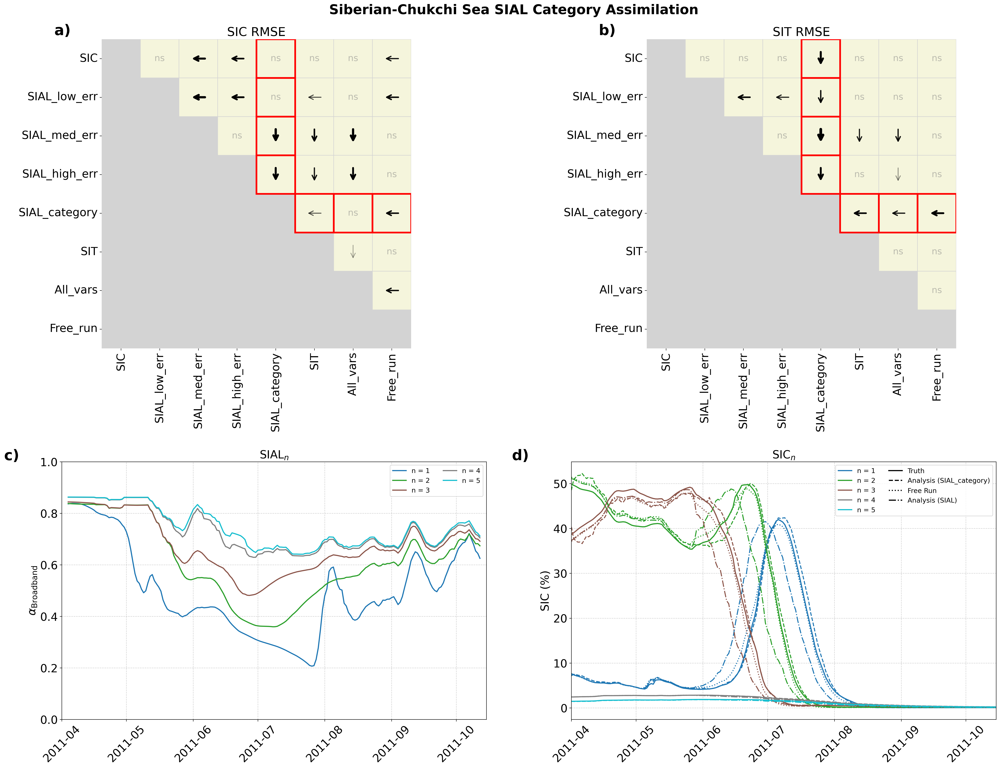

In [17]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind
from matplotlib.patches import Rectangle
import matplotlib.colors as mcolors
import pandas as pd
import xarray as xr
import matplotlib.dates as mdates
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from scipy.stats import mannwhitneyu, wilcoxon, shapiro
from matplotlib.patches import Patch
from matplotlib.cm import ScalarMappable

# ----------- LOAD RMSE DATA (Top Row) -----------
rmse_df = pd.read_csv("/glade/work/jrotondo/Projects/cice-scm-da/data/rmse_results.csv")
metrics = ["SIC", "SIT"]
region = "SibChuk"
full_methods = ["SIC", "SIAL_low_err", "SIAL_med_err", "SIAL_high_err", "SIAL_category", "SIT", "SIT_SIC", "All_vars", "Free_run"]
available_methods = [m for m in full_methods if f"mean_{m}" in rmse_df.columns and not rmse_df[f"mean_{m}"].isna().all()]
alpha = 0.05

# ----------- LOAD TIMESERIES DATA (Bottom Row) -----------
awtvdf, awtvdr = 0.63282, 0.00318
awtidf, awtidr = 0.36218, 0.00182
ensemble_members = [3, 5, 10, 12, 14, 16, 19, 21, 25, 28]
base_path = '/glade/work/jrotondo/Projects/cice-scm-da/data/processed/'
truth_aicen_list, analysis_sial_cat_aicen_list, preassim_aicen_list, analysis_sial_aicen_list = [], [], [], []

for em in ensemble_members:
    paths = {
        "sial_dir": f'{base_path}SIAL_{region}_bounded_med_err_2011_em{em}_s/',
        "sial_cat_dir": f'{base_path}SIAL_{region}_bounded_2011_em{em}_cat/',
        "free_run_dir": f'{base_path}ensemble/free_{region}_final_cat/'
    }

    # Load truth for date alignment
    truth_ds = xr.open_dataset(paths['sial_dir'] + f'truth_data_{em:04d}.nc')
    analysis_sial_cat_ds = xr.open_dataset(paths['sial_cat_dir'] + 'postprocessed_ens.nc')
    analysis_sial_ds = xr.open_dataset(paths['sial_dir'] + 'postprocessed_ens.nc')
    preassim_ds = xr.open_dataset(paths['free_run_dir'] + 'postprocessed_ensemble.nc')

    start_date = np.datetime64('2011-04-01')
    dates = start_date + truth_ds['time'].values.astype('timedelta64[D]')
    dates = dates.astype('datetime64[ns]')
    preassim_ds['time'] = preassim_ds['time'].astype('datetime64[ns]')
    preassim_ds = preassim_ds.sel(time=dates)

    ncat = truth_ds.dims['ncat']
    truth_aicen = truth_ds['aicen'].sel(ni=2).assign_coords(ncat=np.arange(ncat)) * 100
    analysis_sial_cat_aicen = analysis_sial_cat_ds['aicen'].sel(ni=2).mean(dim='ensemble_member').assign_coords(ncat=np.arange(ncat)) * 100
    analysis_sial_aicen = analysis_sial_ds['aicen'].sel(ni=2).mean(dim='ensemble_member').assign_coords(ncat=np.arange(ncat)) * 100
    preassim_aicen = preassim_ds['aicen'].mean(dim='member').assign_coords(ncat=np.arange(ncat)) * 100

    truth_aicen_list.append(truth_aicen)
    analysis_sial_cat_aicen_list.append(analysis_sial_cat_aicen)
    analysis_sial_aicen_list.append(analysis_sial_aicen)
    preassim_aicen_list.append(preassim_aicen)

truth_aicen_avg = xr.concat(truth_aicen_list, dim='ensemble_member').mean(dim='ensemble_member')
analysis_sial_cat_aicen_avg = xr.concat(analysis_sial_cat_aicen_list, dim='ensemble_member').mean(dim='ensemble_member')
analysis_sial_aicen_avg = xr.concat(analysis_sial_aicen_list, dim='ensemble_member').mean(dim='ensemble_member')
preassim_aicen_avg = xr.concat(preassim_aicen_list, dim='ensemble_member').mean(dim='ensemble_member')

analysis_sial_cat = (
    (awtvdr * analysis_sial_cat_ds['alvdrn'] + awtvdf * analysis_sial_cat_ds['alvdfn']) +
    (awtidr * analysis_sial_cat_ds['alidrn'] + awtidf * analysis_sial_cat_ds['alidfn'])
).sel(ni=2).rolling(time=7, center=True).mean()

colors = cm.get_cmap('tab10', ncat)

# ----------- COMBINED FIGURE SETUP -----------
fig = plt.figure(figsize=(30, 22), dpi=300)
gs = fig.add_gridspec(2, 1, height_ratios=[1.2, 1.0], hspace=0.4)

subplot_labels = ['a)', 'b)', 'c)', 'd)']
label_fontsize = 26

# ----------- Top row: RMSE Heatmaps -----------
top_ax_grid = gs[0].subgridspec(1, len(metrics), wspace=0.4)
for m_idx, metric in enumerate(metrics):
    ax = fig.add_subplot(top_ax_grid[m_idx])
    ax.set_title(f"{metric} RMSE", fontsize=22)
    ax.text(-0.1, 1.05, subplot_labels[m_idx], transform=ax.transAxes,
        fontsize=label_fontsize, fontweight='bold', va='top', ha='right')

    region_df = rmse_df[(rmse_df["region"] == region) & (rmse_df["metric"] == metric)]
    method_data = {
        method: region_df[f"mean_{method}"].dropna().values
        for method in available_methods
        if f"mean_{method}" in region_df.columns and not region_df[f"mean_{method}"].isna().all()
    }

    methods = list(method_data.keys())
    n = len(methods)

    base_matrix = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            base_matrix[i, j] = 1 if i >= j else 2

    custom_cmap = mcolors.ListedColormap(["white", "lightgray", "#f5f5dc"])
    sns.heatmap(
        base_matrix,
        xticklabels=methods,
        yticklabels=methods,
        cbar=False,
        annot=False,
        linewidths=0.5,
        linecolor='lightgray',
        square=True,
        ax=ax,
        cmap=custom_cmap,
        vmin=0,
        vmax=2,
        zorder=1
    )

    if "SIAL_category" in methods:
        sial_idx = methods.index("SIAL_category")
        for i in range(n):
            for j in range(n):
                if j > i and (i == sial_idx or j == sial_idx):
                    ax.add_patch(Rectangle((j, i), 1, 1, fill=False, edgecolor='red', lw=3, zorder=2))

    for i in range(n):
        for j in range(n):
            if j <= i:
                continue
            data_i = method_data[methods[i]]
            data_j = method_data[methods[j]]
            if len(data_i) > 1 and len(data_j) > 1:
                p_norm_i = shapiro(data_i).pvalue
                p_norm_j = shapiro(data_j).pvalue
                is_normal = (p_norm_i > 0.05) and (p_norm_j > 0.05)

                if is_normal:
                    test_stat, p_val = ttest_ind(data_i, data_j, equal_var=False)
                else:
                    if len(data_i) == len(data_j):
                        test_stat, p_val = wilcoxon(data_i, data_j, alternative='two-sided')
                    else:
                        test_stat, p_val = mannwhitneyu(data_i, data_j, alternative='two-sided')

                x = j + 0.5
                y = i + 0.5

                if p_val < alpha:
                    mean_i = np.mean(data_i)
                    mean_j = np.mean(data_j)

                    weight = max(1.0, -np.log10(p_val))
                    alpha_val = min(1.0, 0.3 + 0.7 * (1 - p_val / alpha))

                    if mean_i > mean_j:
                        ax.annotate(
                            "", xy=(x, y + 0.2), xytext=(x, y - 0.2),
                            arrowprops=dict(arrowstyle="->", lw=weight, color="black", alpha=alpha_val)
                        )
                    elif mean_j > mean_i:
                        ax.annotate(
                            "", xy=(x - 0.2, y), xytext=(x + 0.2, y),
                            arrowprops=dict(arrowstyle="->", lw=weight, color="black", alpha=alpha_val)
                        )
                else:
                    ax.text(x, y, "ns", ha='center', va='center', fontsize=16, color='grey', alpha=0.5)

# ----------- Bottom row: Timeseries Plots -----------
bottom_ax_grid = gs[1].subgridspec(1, 2, wspace=0.2)
ax1 = fig.add_subplot(bottom_ax_grid[0])
ax2 = fig.add_subplot(bottom_ax_grid[1])

ax1.text(-0.1, 1.05, subplot_labels[2], transform=ax1.transAxes,
         fontsize=label_fontsize, fontweight='bold', va='top', ha='right')

ax2.text(-0.1, 1.05, subplot_labels[3], transform=ax2.transAxes,
         fontsize=label_fontsize, fontweight='bold', va='top', ha='right')

for i in range(ncat):
    ax1.plot(dates,
             analysis_sial_cat.sel(ncat=i).mean(dim='ensemble_member'),
             label=f'n = {i+1}',
             color=colors(i),
             linewidth=2)

ax1.set_title(r'SIAL$_{n}$', fontsize=20)
ax1.set_ylabel(r'$\alpha_{\mathrm{Broadband}}$')
ax1.set_ylim(0, 1)
ax1.grid(True, linestyle='--', alpha=0.6)
ax1.legend(ncol=2, fontsize=12, loc='upper right')

for i in range(ncat):
    ax2.plot(dates, truth_aicen_avg.sel(ncat=i), label=f'n = {i+1}', color=colors(i), linewidth=2)
    ax2.plot(dates, analysis_sial_cat_aicen_avg.sel(ncat=i), linestyle='--', color=colors(i), linewidth=1.8)
    ax2.plot(dates, preassim_aicen_avg.sel(ncat=i), linestyle=':', color=colors(i), linewidth=1.8)
    ax2.plot(dates, analysis_sial_aicen_avg.sel(ncat=i), linestyle='-.', color=colors(i), linewidth=1.8)

ax2.set_title(r'SIC$_{n}$', fontsize=20)
ax2.set_ylabel('SIC (%)')
ax2.grid(True, linestyle='--', alpha=0.6)
custom_lines = [
    Line2D([0], [0], color='black', linestyle='-', linewidth=2, label='Truth'),
    Line2D([0], [0], color='black', linestyle='--', linewidth=2, label='Analysis (SIAL_category)'),
    Line2D([0], [0], color='black', linestyle=':', linewidth=2, label='Free Run'),
    Line2D([0], [0], color='black', linestyle='-.', linewidth=2, label='Analysis (SIAL)')
]
ax2.legend(handles=ax2.get_legend_handles_labels()[0] + custom_lines,
           labels=ax2.get_legend_handles_labels()[1] + [line.get_label() for line in custom_lines],
           ncol=2, fontsize=12, loc='upper right')


for ax in [ax1, ax2]:
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    ax.tick_params(axis='x', rotation=45)
    ax.set_xlim(dates[0], dates[-1])

plt.rcParams.update({'font.size': 18, 'axes.labelsize': 18, 'legend.fontsize': 18})
plt.tight_layout()
fig.suptitle("Siberian-Chukchi Sea SIAL Category Assimilation",
             fontsize=24, fontweight='bold', y=0.92)
plt.show()

# Appendix Figures

## Figure A1: Visualization of the Uncertainty Distributions for Assimilated Sea Ice Variables

This plot provides context to how uncertainty was calculated for different assimilated sea ice variables, and the relative magnitude of each uncertainty.

<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\s'
<>:48: SyntaxWarning: invalid escape sequence '\s'
<>:20: SyntaxWarning: invalid escape sequence '\s'
<>:32: SyntaxWarning: invalid escape sequence '\s'
<>:48: SyntaxWarning: invalid escape sequence '\s'
/glade/derecho/scratch/jrotondo/tmp/ipykernel_22088/4174421247.py:20: SyntaxWarning: invalid escape sequence '\s'
  axs[0, 0].set_ylabel("Uncertainty ($2\sigma$, %)")
/glade/derecho/scratch/jrotondo/tmp/ipykernel_22088/4174421247.py:32: SyntaxWarning: invalid escape sequence '\s'
  axs[0, 1].set_ylabel("Uncertainty ($2\sigma$, m)")
/glade/derecho/scratch/jrotondo/tmp/ipykernel_22088/4174421247.py:48: SyntaxWarning: invalid escape sequence '\s'
  axs[1, 0].set_ylabel("Uncertainty ($2\sigma$)")


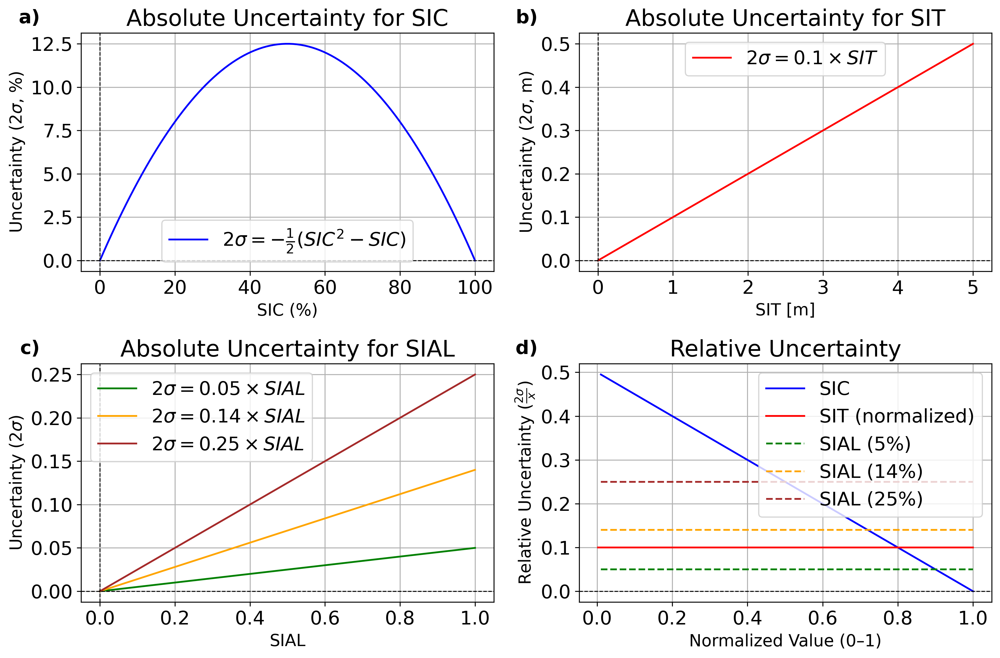

In [25]:
import numpy as np
import matplotlib.pyplot as plt

fig, axs = plt.subplots(2, 2, figsize=(12, 8), dpi=300)

labels = ['a)', 'b)', 'c)', 'd)']
positions = [(0, 0), (0, 1), (1, 0), (1, 1)]

for label, pos in zip(labels, positions):
    axs[pos].text(-0.1, 1.1, label, transform=axs[pos].transAxes,
                  fontsize=16, fontweight='bold', va='top', ha='right')

# === SIC: Absolute Uncertainty ===
sic = np.linspace(0, 1, 100)
sigma_sic = -0.5 * (sic**2 - sic) * 100
axs[0, 0].plot(sic * 100, sigma_sic, label=r'$2\sigma = -\frac{1}{2} (SIC^2 - SIC)$', color='blue')
axs[0, 0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axs[0, 0].axvline(0, color='black', linewidth=0.8, linestyle='--')
axs[0, 0].set_xlabel("SIC (%)")
axs[0, 0].set_ylabel("Uncertainty ($2\sigma$, %)")
axs[0, 0].set_title("Absolute Uncertainty for SIC")
axs[0, 0].legend()
axs[0, 0].grid()

# === SIT: Absolute Uncertainty ===
sit = np.linspace(0, 5, 100)
sigma_sit = 0.1 * sit
axs[0, 1].plot(sit, sigma_sit, label=r'$2\sigma = 0.1 \times SIT$', color='red')
axs[0, 1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axs[0, 1].axvline(0, color='black', linewidth=0.8, linestyle='--')
axs[0, 1].set_xlabel("SIT [m]")
axs[0, 1].set_ylabel("Uncertainty ($2\sigma$, m)")
axs[0, 1].set_title("Absolute Uncertainty for SIT")
axs[0, 1].legend()
axs[0, 1].grid()

# === SIAL: Absolute Uncertainty ===
sial = np.linspace(0, 1, 100)
uncertainty_5 = 0.05 * sial
uncertainty_14 = 0.14 * sial
uncertainty_25 = 0.25 * sial
axs[1, 0].plot(sial, uncertainty_5, label=r'$2\sigma = 0.05 \times SIAL$', color='green')
axs[1, 0].plot(sial, uncertainty_14, label=r'$2\sigma = 0.14 \times SIAL$', color='orange')
axs[1, 0].plot(sial, uncertainty_25, label=r'$2\sigma = 0.25 \times SIAL$', color='brown')
axs[1, 0].axhline(0, color='black', linewidth=0.8, linestyle='--')
axs[1, 0].axvline(0, color='black', linewidth=0.8, linestyle='--')
axs[1, 0].set_xlabel("SIAL")
axs[1, 0].set_ylabel("Uncertainty ($2\sigma$)")
axs[1, 0].set_title("Absolute Uncertainty for SIAL")
axs[1, 0].legend()
axs[1, 0].grid()

# === Relative Uncertainty Plot ===
sic = np.linspace(0.01, 1, 100)
sigma_sic = -0.5 * (sic**2 - sic) * 100
rel_uncert_sic = sigma_sic / (sic * 100)

sit = np.linspace(0.01, 5, 100)
sigma_sit = 0.1 * sit
rel_uncert_sit = sigma_sit / sit

sial = np.linspace(0.01, 1, 100)

axs[1, 1].plot(sic, rel_uncert_sic, label='SIC', color='blue')
axs[1, 1].plot(sit / 5, rel_uncert_sit, label='SIT (normalized)', color='red')
axs[1, 1].plot(sial, [0.05]*len(sial), label='SIAL (5%)', color='green', linestyle='--')
axs[1, 1].plot(sial, [0.14]*len(sial), label='SIAL (14%)', color='orange', linestyle='--')
axs[1, 1].plot(sial, [0.25]*len(sial), label='SIAL (25%)', color='brown', linestyle='--')
axs[1, 1].axhline(0, color='black', linewidth=0.8, linestyle='--')
axs[1, 1].set_xlabel("Normalized Value (0–1)")
axs[1, 1].set_ylabel("Relative Uncertainty ($\\frac{2\\sigma}{x}$)")
axs[1, 1].set_title("Relative Uncertainty")
axs[1, 1].legend()
axs[1, 1].grid()

plt.rcParams.update({'font.size': 16, 'axes.labelsize': 14, 'legend.fontsize': 16})

plt.tight_layout()
plt.show()

## Figure A2: Size of the DA increment when assimilating different sea ice variables

Increment is largest when assimilating SIAL (medium error) and smallest when assimilating SIT.

Processing SIAL...
Processing SIC...
Processing SIT...


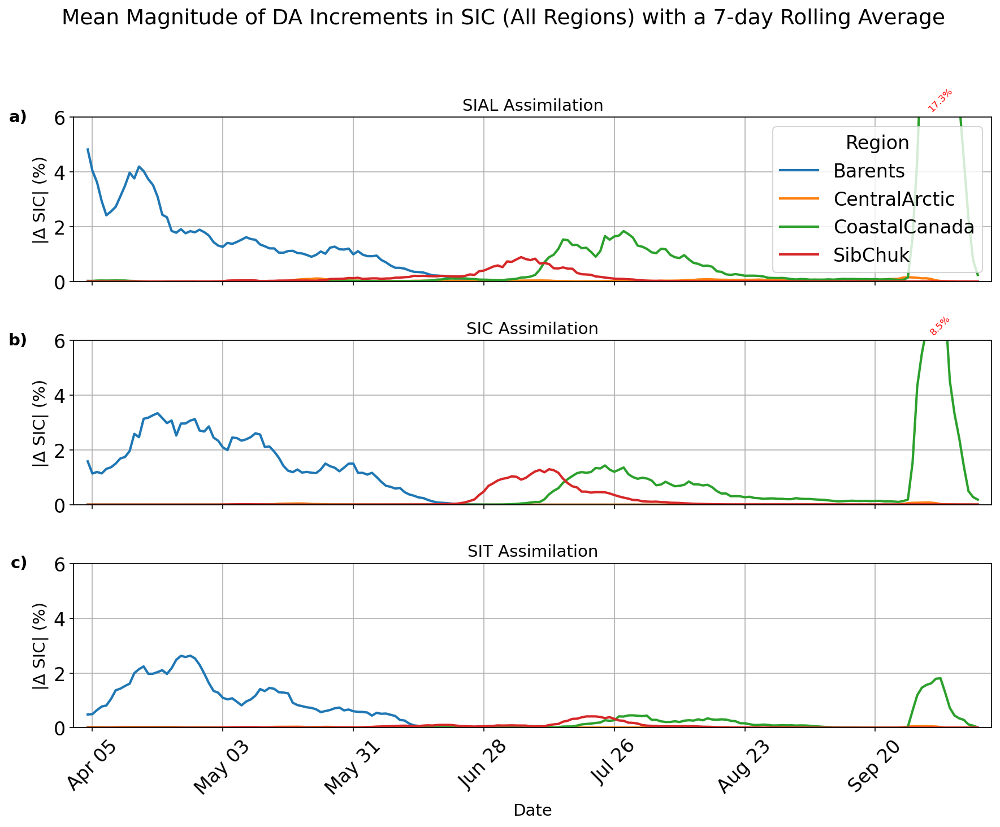

In [26]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# List of ensemble members
ems = [3, 5, 10, 12, 14, 16, 19, 21, 25, 28]
regions = ["Barents", "CentralArctic", "CoastalCanada", "SibChuk"]

# Assimilation type → base path pattern
paths = {
    "SIAL": '/glade/work/jrotondo/Projects/cice-scm-da/data/processed/SIAL_{region}_bounded_med_err_2011_em{em}_s/',
    "SIC": '/glade/work/jrotondo/Projects/cice-scm-da/data/processed/SIC_{region}_bounded_2011_em{em}_f/',
    "SIT": '/glade/work/jrotondo/Projects/cice-scm-da/data/processed/SIT_{region}_bounded_2011_em{em}/',
}

# Time setup
start_date = np.datetime64('2011-04-01')

# Function to compute SIC at ni=2
def compute_sic(ds):
    return ds['aicen'].sel(ni=2).sum(dim='ncat') * 100  # %

# Create figure
fig, axes = plt.subplots(3, 1, figsize=(12, 10), dpi=150, sharex=True)
axes = axes.flatten()

# Add subplot labels a), b), c)
labels = ['a)', 'b)', 'c)']
for ax, label in zip(axes, labels):
    ax.text(-0.05, 1.05, label, transform=ax.transAxes,
            fontsize=14, fontweight='bold', va='top', ha='right')

for ax, (assim_label, path_template) in zip(axes, paths.items()):
    print(f"Processing {assim_label}...")

    for region in regions:
        region_increments = []

        for em in ems:
            path = path_template.format(region=region, em=em)

            try:
                preassim_ds = xr.open_dataset(path + 'preassim_ens.nc')
                analysis_ds = xr.open_dataset(path + 'postprocessed_ens.nc')
            except FileNotFoundError:
                print(f"⚠️ Missing files for {region}, em{em} in {assim_label}, skipping.")
                continue

            # Compute SIC and increment
            preassim_sic = compute_sic(preassim_ds).mean(dim='ensemble_member')
            analysis_sic = compute_sic(analysis_ds).mean(dim='ensemble_member')
            increment = analysis_sic - preassim_sic

            region_increments.append(np.abs(increment))

        if region_increments:
            increments_stack = xr.concat(region_increments, dim='em')
            mean_abs_increment = increments_stack.mean(dim='em')
            # smooth over 7 days
            mean_abs_increment = mean_abs_increment.rolling(time=7, center=True).mean()
            dates = start_date + analysis_ds['time'].values.astype('timedelta64[D]')

            # Plot the increment line
            ax.plot(dates, mean_abs_increment, label=region, lw=2)

            # Annotate max value > 6 (if any)
            above_6 = mean_abs_increment > 6
            if above_6.any():
                max_idx = mean_abs_increment.where(above_6).argmax().item()
                max_val = mean_abs_increment[max_idx].item()
                max_date = dates[max_idx]

                ax.annotate(f"{max_val:.1f}" + "%", xy=(max_date, 6), xytext=(0, 5),
                            textcoords="offset points", ha='center', fontsize=8,
                            color='red', rotation=45, clip_on=False)

    ax.set_title(f'{assim_label} Assimilation', fontsize=14)
    ax.set_ylabel('|Δ SIC| (%)')
    ax.grid(True)
    if assim_label == 'SIAL':
        ax.legend(title='Region')
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax.xaxis.set_major_locator(mdates.WeekdayLocator(interval=4))
    ax.set_xlim(dates[0], dates[-1])
    ax.set_ylim(0, 6)
    ax.tick_params(axis='x', rotation=45)

axes[-1].set_xlabel('Date')
plt.suptitle('Mean Magnitude of DA Increments in SIC (All Regions) with a 7-day Rolling Average', fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Supplemental Figures

## Figure S1: Determining the Impact of Random Observational Noise on Assimilation Uncertainty

This plot shows that the assimilation results are likely independent of observational noise. SIAL assimilation is tested using three different sets of randomly generated noisy observations using the same distribution of $2\sigma$ to reveal almost identical results when averaged over region.


===== RMSE Summary (Mean ± 95% CI) over 6 ensemble members =====

SIC RMSE (%):
  Obs Noise 1: 5.650 ± 1.170 (%)
  Obs Noise 2: 5.658 ± 1.167 (%)
  Obs Noise 3: 5.658 ± 1.167 (%)

SIT RMSE (m):
  Obs Noise 1: 0.226 ± 0.045 (m)
  Obs Noise 2: 0.226 ± 0.045 (m)
  Obs Noise 3: 0.226 ± 0.045 (m)


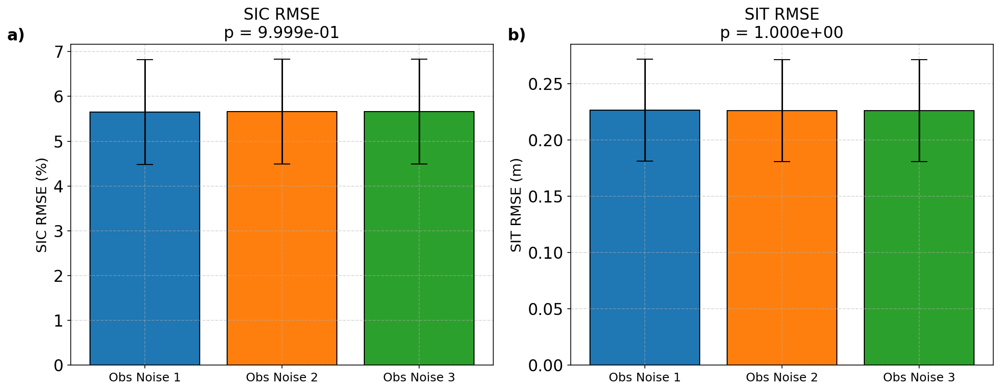

In [28]:
import xarray as xr
import numpy as np
import os
from scipy import stats

def compute_rmse(analysis, truth):
    return np.sqrt(((analysis - truth) ** 2).where(~np.isnan(analysis - truth), drop=True).mean())

def mean_and_ci(data, confidence=0.95):
    a = np.array(data)
    n = len(a)
    m = np.mean(a)
    se = stats.sem(a)
    h = se * stats.t.ppf((1 + confidence) / 2., n - 1)
    return m, h

# Setup
base_dir = "/glade/work/jrotondo/Projects/cice-scm-da/data/processed/"
regions = ["Barents", "CentralArctic", "CoastalCanada", "SibChuk"]
sic_cutoffs = {"Barents": 0.032, "CentralArctic": 0, "CoastalCanada": 0.018, "SibChuk": 0.173}
years_em = {2011: [3, 5, 10, 14, 16, 21, 28]}  # 6 ensemble members
dirs_to_plot = [
    "SIAL_{Region}_bounded_med_err_2011_em{em}_s",
    "SIAL_{Region}_bounded_med_err_2011_em{em}_t",
    "SIAL_{Region}_bounded_med_err_2011_em{em}_u"
]

# Initialize storage
rmse_summary = {'SIC': {1: [], 2: [], 3: []}, 'SIT': {1: [], 2: [], 3: []}}

# Loop through regions, ensembles, and noise levels
for region in regions:
    sic_cutoff = sic_cutoffs.get(region, 0)
    for em in years_em[2011]:
        rmse_sic_vals = []
        rmse_sit_vals = []

        for noise_idx, dir_format in enumerate(dirs_to_plot, start=1):
            data_dir = f"{base_dir}{dir_format}".format(Region=region, em=em)
            truth_file = f"{data_dir}/truth_data_{em:04d}.nc"
            analysis_file = f"{data_dir}/analysis_ens.nc"

            if not (os.path.exists(truth_file) and os.path.exists(analysis_file)):
                print(f"Skipping {region}, em {em}, noise {noise_idx}: missing files.")
                continue

            truth_ds = xr.open_dataset(truth_file)
            analysis_ds = xr.open_dataset(analysis_file)

            # Align time
            common_time = np.intersect1d(truth_ds['time'], analysis_ds['time'])
            if len(common_time) == 0:
                print(f"Skipping {region}, em {em}, noise {noise_idx}: no common time.")
                continue

            truth_ds = truth_ds.sel(time=common_time)
            analysis_ds = analysis_ds.sel(time=common_time)

            # SIC
            sic_truth = truth_ds['aicen'].sum(dim='ncat').sel(ni=2) * 100
            sic_analysis = analysis_ds['aicen'].sum(dim='ncat').sel(ni=2) * 100
            rmse_sic = compute_rmse(sic_analysis, sic_truth)
            rmse_summary['SIC'][noise_idx].append(rmse_sic.item())

            # SIT
            sit_truth = truth_ds['vicen'].sum(dim='ncat').sel(ni=2) / truth_ds['aicen'].sum(dim='ncat').sel(ni=2)
            sit_analysis = analysis_ds['vicen'].sum(dim='ncat').sel(ni=2) / analysis_ds['aicen'].sum(dim='ncat').sel(ni=2)
            sit_analysis = xr.where(analysis_ds['aicen'].sum(dim='ncat').sel(ni=2) < sic_cutoff, np.nan, sit_analysis)
            rmse_sit = compute_rmse(sit_analysis, sit_truth)
            rmse_summary['SIT'][noise_idx].append(rmse_sit.item())

# Print results
print("\n===== RMSE Summary (Mean ± 95% CI) over 6 ensemble members =====")
for metric in ['SIC', 'SIT']:
    unit = "%" if metric == "SIC" else "m"
    print(f"\n{metric} RMSE ({unit}):")
    for obs_noise in [1, 2, 3]:
        vals = rmse_summary[metric][obs_noise]
        if len(vals) >= 2:
            mean, ci = mean_and_ci(vals)
            print(f"  Obs Noise {obs_noise}: {mean:.3f} ± {ci:.3f} ({unit})")
        else:
            print(f"  Obs Noise {obs_noise}: Not enough data")

import matplotlib.pyplot as plt
from scipy.stats import f_oneway

# Compute means, CIs, and ANOVA p-values
summary_stats = {}
for metric in ['SIC', 'SIT']:
    means, cis = [], []
    for obs_noise in [1, 2, 3]:
        vals = rmse_summary[metric][obs_noise]
        m, h = mean_and_ci(vals)
        means.append(m)
        cis.append(h)
    summary_stats[metric] = {'means': means, 'cis': cis}
    
# p-values using ANOVA (tests if means are significantly different across noise levels)
pvals = {}
for metric in ['SIC', 'SIT']:
    vals = [rmse_summary[metric][i] for i in [1, 2, 3]]
    _, p = f_oneway(*vals)
    pvals[metric] = p

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6), dpi=150, sharey=False)
colors = ['#1f77b4', '#ff7f0e', '#2ca02c']
x = np.arange(3)
noise_labels = ['Obs Noise 1', 'Obs Noise 2', 'Obs Noise 3']
panel_labels = ['a)', 'b)']

for idx, metric in enumerate(['SIC', 'SIT']):
    means = summary_stats[metric]['means']
    cis = summary_stats[metric]['cis']
    ax = axes[idx]
    ax.bar(x, means, yerr=cis, capsize=8, color=colors, edgecolor='k')
    ax.set_xticks(x)
    ax.set_xticklabels(noise_labels, fontsize=12)
    ax.set_title(f'{metric} RMSE\np = {pvals[metric]:.3e}', fontsize=16)
    ax.set_ylabel(f'{metric} RMSE ({ "%" if metric=="SIC" else "m" })', fontsize=14)
    ax.text(-0.15, 1.05, panel_labels[idx], transform=ax.transAxes,
            fontsize=16, fontweight='bold', va='top', ha='left')
    ax.grid(True, linestyle='--', alpha=0.5)

#plt.suptitle("RMSE by Applying 3 Sets of Random Observational Noise (Mean ± 95% CI)", fontsize=18)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## Figure S2: SIT RMSE Calculation based on SIT Cutoffs

This plot reveals how the SIC cutoffs for each region were determined when calculating the SIT RMSE. We essentially looked for the first location in which the RMSE decreased below a minimum slope of 0.01, also ensuring that this slope remained less than 0.01 for some time after this initial point.


Processing Region: Barents
  Processing ensemble member: 3
  Processing ensemble member: 5
  Processing ensemble member: 10
  Processing ensemble member: 12
  Processing ensemble member: 14
  Processing ensemble member: 16
  Processing ensemble member: 19
  Processing ensemble member: 21
  Processing ensemble member: 25
  Processing ensemble member: 28

Processing Region: CentralArctic
  Processing ensemble member: 3
  Processing ensemble member: 5
  Processing ensemble member: 10
  Processing ensemble member: 12
  Processing ensemble member: 14
  Processing ensemble member: 16
  Processing ensemble member: 19
  Processing ensemble member: 21
  Processing ensemble member: 25
  Processing ensemble member: 28

Processing Region: CoastalCanada
  Processing ensemble member: 3
  Processing ensemble member: 5
  Processing ensemble member: 10
  Processing ensemble member: 12
  Processing ensemble member: 14
  Processing ensemble member: 16
  Processing ensemble member: 19
  Processing ensemb

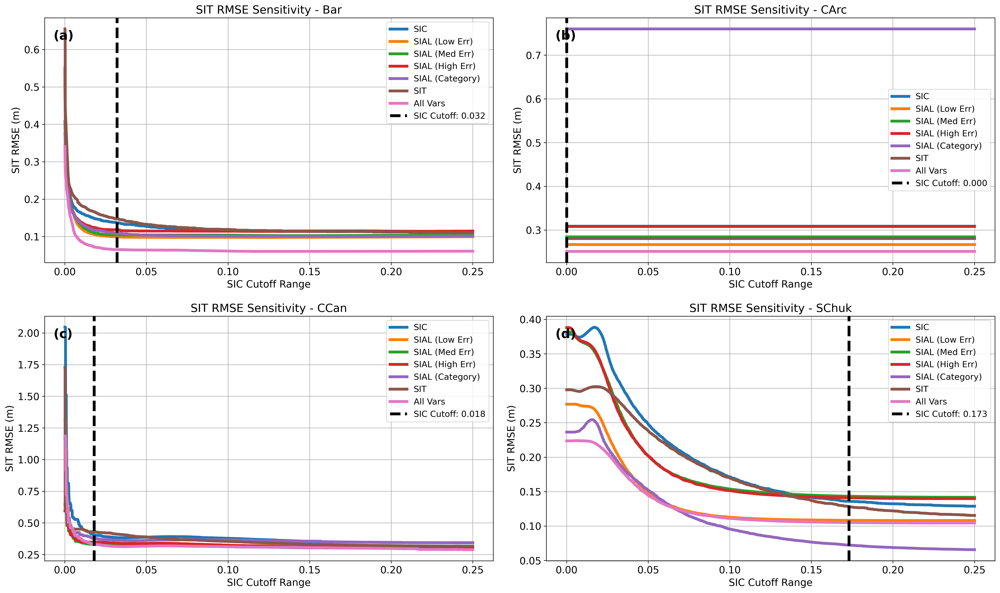

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import os
import pandas as pd

# Define directories and ensemble sizes for each year
base_dir = "/glade/work/jrotondo/Projects/cice-scm-da/data/processed/"
years_em = {2011: 3, 2012: 5, 2013: 10, 2015: 14, 2017: 16, 2019: 21}

# Regions to process
regions = ["Barents", "CentralArctic", "CoastalCanada", "SibChuk"]
abbreviated_regions = ["Bar", "CArc", "CCan", "SChuk"]

# SIC cutoffs to test
sic_cutoffs = np.linspace(0.0001, 0.25, 5000)

# Storage for RMSE values per region and assimilation case
rmse_results = {region: {key: [] for key in ["SIC", "SIAL (Low Err)", "SIAL (Med Err)", 
                                             "SIAL (High Err)", "SIAL (Category)", "SIT", "All Vars"]} for region in regions}

# Function to compute RMSE
def compute_rmse(analysis, truth):
    return np.sqrt(((analysis - truth) ** 2).mean().values)

# Loop over regions
for region in regions:
    em_max = years_em[2011]  # Override all years to 2011

    print(f"\nProcessing Region: {region}")

    # Initialize storage for averaging over ensemble members
    rmse_sums = {key: np.zeros(len(sic_cutoffs)) for key in rmse_results[region]}
    valid_ensemble_count = {key: np.zeros(len(sic_cutoffs)) for key in rmse_results[region]}
    
    for em in [3, 5, 10, 12, 14, 16, 19, 21, 25, 28]:  # Loop over all ensemble members
        print(f"  Processing ensemble member: {em}")

        # Define directories
        albedo_low_error_dir = f"{base_dir}SIAL_{region}_bounded_low_err_2011_em{em}"
        albedo_med_error_dir = f"{base_dir}SIAL_{region}_bounded_med_err_2011_em{em}_s"
        albedo_high_error_dir = f"{base_dir}SIAL_{region}_bounded_high_err_2011_em{em}_f"
        albedo_category_dir = f"{base_dir}SIAL_{region}_bounded_2011_em{em}_cat"
        sic_dir = f"{base_dir}SIC_{region}_bounded_2011_em{em}_f"
        sit_dir = f"{base_dir}SIT_{region}_bounded_2011_em{em}"
        everything_dir = f"{base_dir}EVERYTHING_{region}_bounded_med_err_2011_em{em}_f"

        # File paths
        truth_file = f"{sic_dir}/truth_data_{em:04d}.nc"
        analysis_files = {
            "SIC": f"{sic_dir}/analysis_ens.nc",
            "SIAL (Low Err)": f"{albedo_low_error_dir}/analysis_ens.nc",
            "SIAL (Med Err)": f"{albedo_med_error_dir}/analysis_ens.nc",
            "SIAL (High Err)": f"{albedo_high_error_dir}/analysis_ens.nc",
            "SIAL (Category)": f"{albedo_category_dir}/analysis_ens.nc",
            "SIT": f"{sit_dir}/analysis_ens.nc",
            "All Vars": f"{everything_dir}/analysis_ens.nc"
        }

        # Check if all files exist
        if not os.path.exists(truth_file) or not all(os.path.exists(f) for f in analysis_files.values()):
            print(f"    Skipping Em {em} due to missing files.")
            continue

        # Load datasets
        truth_ds = xr.open_dataset(truth_file)
        analysis_ds = {key: xr.open_dataset(path) for key, path in analysis_files.items()}

        # Compute common time
        common_time = truth_ds['time'].values
        for ds in analysis_ds.values():
            common_time = np.intersect1d(common_time, ds['time'].values)

        if len(common_time) == 0:
            print(f"    Skipping Em {em}: No common time values found!")
            continue

        # Select common times
        truth_ds = truth_ds.sel(time=common_time)
        for key in analysis_ds:
            analysis_ds[key] = analysis_ds[key].sel(time=common_time)

        # Extract SIT values
        sit_truth = truth_ds['vicen'].sum(dim='ncat').sel(ni=2) / truth_ds['aicen'].sum(dim='ncat').sel(ni=2)
        sit_analysis = {key: ds['vicen'].sum(dim='ncat').sel(ni=2) / ds['aicen'].sum(dim='ncat').sel(ni=2) 
                        for key, ds in analysis_ds.items()}

        # Loop through SIC cutoffs
        for i, sic_cutoff in enumerate(sic_cutoffs):
            for key, sit_data in sit_analysis.items():
                valid_mask = analysis_ds[key]["aicen"].sum(dim="ncat").sel(ni=2) >= sic_cutoff
                sit_filtered = sit_data.where(valid_mask)
                sit_truth_filtered = sit_truth.where(valid_mask)
                
                rmse_value = compute_rmse(sit_filtered, sit_truth_filtered)
                if not np.isnan(rmse_value):
                    rmse_sums[key][i] += rmse_value
                    valid_ensemble_count[key][i] += 1

    # Average RMSE across ensemble members
    for key in rmse_results[region]:
        valid_count = valid_ensemble_count[key]
        valid_count[valid_count == 0] = 1  # Avoid division by zero
        rmse_results[region][key] = (rmse_sums[key] / valid_count).tolist()

# Compute slopes and find cutoff for each region
cutoff_points = {}

for region in regions:
    avg_slopes = []

    for key in rmse_results[region]:
        values = np.array(rmse_results[region][key])
        slopes = np.diff(values) / np.diff(sic_cutoffs)
        avg_slopes.append(slopes)

    avg_slopes = np.mean(avg_slopes, axis=0)  # Average across all RMSE curves

    # Compute rolling average of slopes for each region
    rolling_avg_slopes = pd.Series(avg_slopes).rolling(window=3, min_periods=1).mean().to_numpy()
    abs_rolling_avg_slopes = np.abs(rolling_avg_slopes)  # Ensure positive values

    try:
        # Find valid cutoff indices where slope < 0.1
        valid_indices = np.where(abs_rolling_avg_slopes < 0.01)[0]

        for idx in valid_indices:
            if idx + 1 < len(sic_cutoffs):  # Ensure index is within range
                future_sic = sic_cutoffs[idx] + 0.05

                # Find the closest SIC index for (current SIC + 0.05)
                future_idx = np.searchsorted(sic_cutoffs, future_sic, side='right')

                if future_idx < len(sic_cutoffs) and abs_rolling_avg_slopes[future_idx] < 0.01:
                    cutoff_value = sic_cutoffs[idx]
                    print(f"Cutoff Found for {region}: {cutoff_value:.3f}")
                    cutoff_points[region] = round(cutoff_value, 3)
                    break  # Stop after finding first valid cutoff

        else:
            raise IndexError  # No valid cutoff found

    except IndexError:
        cutoff_points[region] = None  # No valid cutoff found
        print("No valid cutoff found!")

# Plot results with vertical cutoff lines
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 12), dpi=300)

subplot_labels = ['(a)', '(b)', '(c)', '(d)']
for ax, region, abbrev_region, label in zip(axes.flatten(), regions, abbreviated_regions, subplot_labels):
    # Add subplot label in the upper left corner
    ax.text(0.02, 0.95, label, transform=ax.transAxes, fontsize=18, fontweight='bold', va='top', ha='left')

    for line_label, values in rmse_results[region].items():
        ax.plot(sic_cutoffs, values, linestyle='-', linewidth=4, label=line_label)

    if cutoff_points[region] is not None:
        ax.axvline(cutoff_points[region], color='black', linestyle='dashed', linewidth=4, label=f"SIC Cutoff: {cutoff_points[region]:.3f}")

    ax.set_xlabel(f"SIC Cutoff Range", fontsize=14)
    ax.set_ylabel("SIT RMSE (m)", fontsize=14)
    ax.set_title(f"SIT RMSE Sensitivity - {abbrev_region}", fontsize=16)
    ax.legend(fontsize=12)
    ax.grid(True)
    ax.tick_params(axis='both', which='major', labelsize=14)

plt.rcParams.update({'font.size': 18})
plt.rcParams.update({'xtick.labelsize': 18})
plt.tight_layout()
plt.show()

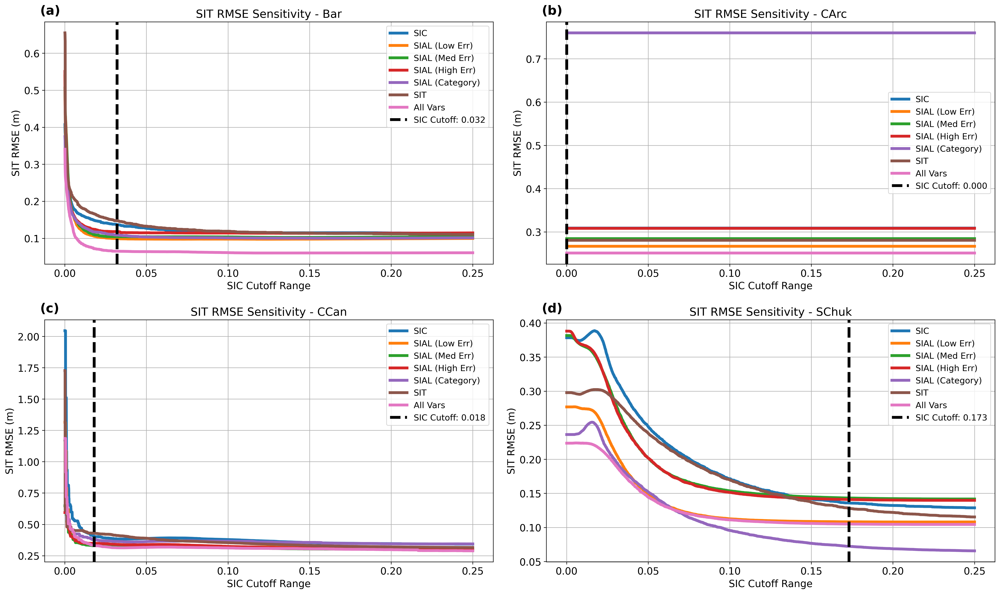

In [5]:
# Plot results with vertical cutoff lines
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(20, 12), dpi=300)

subplot_labels = ['(a)', '(b)', '(c)', '(d)']
for ax, region, abbrev_region, label in zip(axes.flatten(), regions, abbreviated_regions, subplot_labels):
    # Add subplot label in the upper left corner
    ax.text(-0.01, 1.07, label, transform=ax.transAxes, fontsize=18, fontweight='bold', va='top', ha='left')

    for line_label, values in rmse_results[region].items():
        ax.plot(sic_cutoffs, values, linestyle='-', linewidth=4, label=line_label)

    if cutoff_points[region] is not None:
        ax.axvline(cutoff_points[region], color='black', linestyle='dashed', linewidth=4, label=f"SIC Cutoff: {cutoff_points[region]:.3f}")

    ax.set_xlabel(f"SIC Cutoff Range", fontsize=14)
    ax.set_ylabel("SIT RMSE (m)", fontsize=14)
    ax.set_title(f"SIT RMSE Sensitivity - {abbrev_region}", fontsize=16)
    ax.legend(fontsize=12)
    ax.grid(True)
    ax.tick_params(axis='both', which='major', labelsize=14)

plt.rcParams.update({'font.size': 18})
plt.rcParams.update({'xtick.labelsize': 18})
plt.tight_layout()
plt.show()